In [1]:
get_ipython().run_line_magic('matplotlib', 'inline')
"""Validation-only instrumentation injected into fresh kernels, never into the build."""
import copy as __v_copy
import pickle as __v_pickle
import random as __v_random
import sys as __v_sys
from pathlib import Path as __v_Path
import numpy as __v_np
import pandas as __v_pd
import matplotlib.pyplot as __v_plt
from IPython.display import display as __v_original_display

__v_np.random.seed(42)
__v_random.seed(42)
__v_displays = []
__v_plots = []


def __v_display(*objects, **kwargs):
    for obj in objects:
        if isinstance(obj, (__v_pd.DataFrame, __v_pd.Series)):
            __v_displays.append(obj.copy(deep=True))
        elif type(obj).__name__ == 'Styler' and isinstance(obj.data, __v_pd.DataFrame):
            __v_displays.append(obj.data.copy(deep=True))
    return __v_original_display(*objects, **kwargs)


display = __v_display
__v_original_show = __v_plt.show


def __v_show(*args, **kwargs):
    for num in __v_plt.get_fignums():
        fig = __v_plt.figure(num)
        axes = []
        for ax in fig.axes:
            axes.append({
                'title': ax.get_title(), 'xlabel': ax.get_xlabel(), 'ylabel': ax.get_ylabel(),
                'xlim': ax.get_xlim(), 'ylim': ax.get_ylim(),
                'xscale': ax.get_xscale(), 'yscale': ax.get_yscale(),
                'lines': [{'xy': line.get_xydata().copy(), 'color': line.get_color(),
                           'style': line.get_linestyle()} for line in ax.lines],
                'collections': [{'array': __v_copy.deepcopy(col.get_array()),
                                 'offsets': __v_copy.deepcopy(col.get_offsets()),
                                 'paths': [path.vertices.copy() for path in col.get_paths()],
                                 'facecolors': col.get_facecolors().copy()}
                                for col in ax.collections],
                'patches': [{'vertices': patch.get_path().vertices.copy(),
                             'transform': patch.get_patch_transform().get_matrix().copy(),
                             'facecolor': patch.get_facecolor()} for patch in ax.patches],
                'images': [__v_copy.deepcopy(image.get_array()) for image in ax.images],
                'texts': [(text.get_text(), text.get_position()) for text in ax.texts],
                'xticks': [t.get_text() for t in ax.get_xticklabels()],
                'yticks': [t.get_text() for t in ax.get_yticklabels()],
            })
        __v_plots.append({'size': fig.get_size_inches().copy(), 'axes': axes})
    return __v_original_show(*args, **kwargs)


__v_plt.show = __v_show


def __v_capture(value, depth=0):
    if depth > 8:
        raise TypeError('Not a data result')
    if isinstance(value, (__v_pd.DataFrame, __v_pd.Series, __v_pd.Index)):
        return __v_copy.deepcopy(value)
    if isinstance(value, __v_np.ndarray):
        if value.dtype.hasobject:
            # Preserve actual object data (e.g. category labels), not UI handles
            for item in value.flat:
                __v_capture(item, depth + 1)
        return __v_copy.deepcopy(value)
    if value is None or isinstance(value, (str, int, float, bool, __v_np.generic)):
        return value
    if isinstance(value, dict):
        return {key: __v_capture(item, depth + 1) for key, item in value.items()}
    if isinstance(value, (list, tuple, set)):
        items = sorted(value) if isinstance(value, set) else value
        return [__v_capture(item, depth + 1) for item in items]
    raise TypeError('Not a data result')


def __v_finish(filename):
    values = {}
    for name, value in list(globals().items()):
        if name.startswith('_') or name in {'In', 'Out'}:
            continue
        try:
            values[name] = __v_capture(value)
        except (TypeError, ValueError):
            pass
    with open(filename, 'wb') as handle:
        __v_pickle.dump({'tables': __v_displays, 'plots': __v_plots, 'values': values}, handle)


Matplotlib is building the font cache; this may take a moment.


# Модель классификации для задачи оценки риска


### 0 Предварительный анализ

Цель этапа — уточнить семантику столбцов, чтобы корректно поставить задачу

Исходные описания столбцов короткие: в них не указаны единицы измерения и значения категорий, не везде понятно, как читать числа

Поэтому загружаем данные, определяем типы и домены значений и на их основе интерпретируем каждый столбец


#### 0.1 Исходные описания и загрузка данных

От автора датасета есть только короткие англоязычные описания столбцов (с Kaggle)


In [2]:
import pandas as pd

# убираем незначащие нули
pd.set_option('display.float_format',
              lambda x: f'{x:.6f}'.rstrip('0').rstrip('.'))
# не обрезаем длинный текст в ячейках таблиц
pd.set_option('display.max_colwidth', None)


def fmt_number(x):
    return f'{x:.6f}'.rstrip('0').rstrip('.')


# описания столбцов от автора датасета
source_descriptions = {
    'person_age': 'Age',
    'person_income': 'Annual Income',
    'person_home_ownership': 'Home ownership',
    'person_emp_length': 'Employment length (in years)',
    'loan_intent': 'Loan intent',
    'loan_grade': 'Loan grade',
    'loan_amnt': 'Loan amount',
    'loan_int_rate': 'Interest rate',
    'loan_status': 'Loan status (0 is non default 1 is default)',
    'loan_percent_income': 'Percent income',
    'cb_person_default_on_file': 'Historical default',
    'cb_person_cred_hist_length': 'Credit history length',
}

data_raw = pd.read_csv('./data/credit_risk_dataset.csv')
data = data_raw.copy()

display(pd.Series(source_descriptions, name='Описание из источника').to_frame())

,Описание из источника
person_age,Age
person_income,Annual Income
person_home_ownership,Home ownership
person_emp_length,Employment length (in years)
loan_intent,Loan intent
loan_grade,Loan grade
loan_amnt,Loan amount
loan_int_rate,Interest rate
loan_status,Loan status (0 is non default 1 is default)
loan_percent_income,Percent income


#### 0.2 Типы и домены значений

Для каждого столбца определяем по данным фактический тип, число различных значений и домен: диапазон [min, max] для числовых, множество значений для категориальных


In [3]:
# столбец считаем категориальным, если он нечисловой или у него мало различных значений
MAX_CATEGORIES = 10

def is_categorical(column):
    values = data[column]
    return not pd.api.types.is_numeric_dtype(values) or values.nunique() <= MAX_CATEGORIES


def domain(column):
    values = data[column].dropna()
    if is_categorical(column):
        return '{' + ', '.join(str(v) for v in sorted(values.unique())) + '}'
    return f'[{fmt_number(values.min())}, {fmt_number(values.max())}]'


columns_info = pd.DataFrame(index=data.columns)
columns_info['Описание из источника'] = columns_info.index.map(source_descriptions)
columns_info['Тип в данных'] = data.dtypes.astype(str)
columns_info['Домен'] = columns_info.index.map(domain)

categorical = columns_info.index.map(is_categorical)
display(columns_info[~categorical].style.set_caption('Числовые столбцы'))
display(columns_info[categorical].style.set_caption('Категориальные столбцы'))

,Описание из источника,Тип в данных,Домен
person_age,Age,int64,"[20, 144]"
person_income,Annual Income,int64,"[4000, 6000000]"
person_emp_length,Employment length (in years),float64,"[0, 123]"
loan_amnt,Loan amount,int64,"[500, 35000]"
loan_int_rate,Interest rate,float64,"[5.42, 23.22]"
loan_percent_income,Percent income,float64,"[0, 0.83]"
cb_person_cred_hist_length,Credit history length,int64,"[2, 30]"


,Описание из источника,Тип в данных,Домен
person_home_ownership,Home ownership,str,"{MORTGAGE, OTHER, OWN, RENT}"
loan_intent,Loan intent,str,"{DEBTCONSOLIDATION, EDUCATION, HOMEIMPROVEMENT, MEDICAL, PERSONAL, VENTURE}"
loan_grade,Loan grade,str,"{A, B, C, D, E, F, G}"
loan_status,Loan status (0 is non default 1 is default),int64,"{0, 1}"
cb_person_default_on_file,Historical default,str,"{N, Y}"


#### 0.3 Интерпретация столбцов

На основании описания из источника и доменов значений делаем развёрнутые описания столбцов и определяем типы категориальных признаков

_Дефолт — неисполнение заёмщиком обязательств по кредиту: прекращение платежей или существенная просрочка_


In [4]:
# порядок категорий из данных не выводится — задаём вручную
ORDINAL_COLUMNS = {'loan_grade'}

def semantic_type(column):
    if not is_categorical(column):
        return 'числовой'
    if data[column].nunique() == 2:
        return 'бинарный'
    if column in ORDINAL_COLUMNS:
        return 'порядковый'
    return 'номинальный'


# уточнённые описания: единицы измерения, расшифровка значений
interpretations = {
    'person_age': 'возраст заёмщика, лет',
    'person_income': 'годовой доход',
    'person_home_ownership': 'жильё:\n'
                             '• RENT — снимает\n'
                             '• OWN — своё\n'
                             '• MORTGAGE — в ипотеке\n'
                             '• OTHER — другое',
    'person_emp_length': 'стаж на текущей работе, лет',
    'loan_intent': 'цель кредита:\n'
                   '• PERSONAL — личные нужды\n'
                   '• EDUCATION — образование\n'
                   '• MEDICAL — лечение\n'
                   '• VENTURE — бизнес\n'
                   '• HOMEIMPROVEMENT — ремонт жилья\n'
                   '• DEBTCONSOLIDATION — рефинансирование других долгов',
    'loan_grade': 'грейд займа от A (надёжный) до G (рискованный)',
    'loan_amnt': 'сумма кредита',
    'loan_int_rate': 'процентная ставка, % годовых',
    'loan_status': 'статус кредита:\n'
                   '• 0 — платит\n'
                   '• 1 — дефолт',
    'loan_percent_income': 'доля кредита от годового дохода',
    'cb_person_default_on_file': 'были ли дефолты раньше (по данным кредитного бюро):\n'
                                 '• Y — были\n'
                                 '• N — не было',
    'cb_person_cred_hist_length': 'длина кредитной истории, лет',
}

columns_info['Фактический тип'] = columns_info.index.map(semantic_type)
columns_info['Описание'] = columns_info.index.map(interpretations)
display(columns_info[['Описание из источника', 'Описание', 'Фактический тип']]
        .style.set_properties(**{'white-space': 'pre-line', 'text-align': 'left'}))

,Описание из источника,Описание,Фактический тип
person_age,Age,"возраст заёмщика, лет",числовой
person_income,Annual Income,годовой доход,числовой
person_home_ownership,Home ownership,жильё: • RENT — снимает • OWN — своё • MORTGAGE — в ипотеке • OTHER — другое,номинальный
person_emp_length,Employment length (in years),"стаж на текущей работе, лет",числовой
loan_intent,Loan intent,цель кредита: • PERSONAL — личные нужды • EDUCATION — образование • MEDICAL — лечение • VENTURE — бизнес • HOMEIMPROVEMENT — ремонт жилья • DEBTCONSOLIDATION — рефинансирование других долгов,номинальный
loan_grade,Loan grade,грейд займа от A (надёжный) до G (рискованный),порядковый
loan_amnt,Loan amount,сумма кредита,числовой
loan_int_rate,Interest rate,"процентная ставка, % годовых",числовой
loan_status,Loan status (0 is non default 1 is default),статус кредита: • 0 — платит • 1 — дефолт,бинарный
loan_percent_income,Percent income,доля кредита от годового дохода,числовой


### 1 Постановка задачи


#### Интерпретация

Ввиду нескольких возможных интерпретаций задачи и датасета, остановимся на таком варианте:

Заёмщик делает заявку на кредит, предоставляя кредитору свои данные, желаемую сумму, цель займа и так далее

Кредитор выставляет потенциальному займу рейтинг (loan_grade) и на его основе предлагает процентную ставку (loan_int_rate)

Кредитор делает это с помощью собственного прогноза — своей моделью или вручную

При этом можно полагать, что кредитору доступно гораздо больше признаков, чем представлено в датасете нам, поэтому loan_grade (и связанный с ним loan_int_rate) — это выжимка из большего набора признаков, и мы её учитываем в нашей модели

loan_status, с другой стороны, — реальный факт, перестал ли заёмщик платить; наша модель будет предсказывать именно его

Зачем это нужно? — К примеру, если кредитор выступает посредником между заёмщиком и инвесторами, которые на основе оценки кредитора и ограниченных данных о займе и заёмщике сами решают, финансировать ли кредит

В этом случае инвестор нуждается в нашей модели, чтобы оценивать свои риски

Итак, задача — предсказывать значение loan_status на новых данных (все остальные столбцы — признаки)

Поскольку поле loan_status бинарное, это задача классификации, а конкретно бинарной классификации


### 2 Разведочный анализ


#### 2.1 Общий обзор: загружаем датасет, получаем базовое описание, смотрим на примеры записей


In [5]:
data_shape = data.shape
base_props = pd.DataFrame([data_shape[0], data_shape[1], data_shape[1] - 1, 1], index=['Записей',
                         'Переменных', 'Признаков', 'Целевых переменных'], columns=['Количество'])

display(base_props)
display(data.head(3))
display(data.sample(3))
display(data.tail(3))


,Количество
Записей,32581
Переменных,12
Признаков,11
Целевых переменных,1


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5,EDUCATION,B,1000,11.14,0,0.1,N,2
2,25,9600,MORTGAGE,1,MEDICAL,C,5500,12.87,1,0.57,N,3


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
14668,24,28000,OWN,6,HOMEIMPROVEMENT,B,10000,10.37,0,0.36,N,2
24614,27,64000,RENT,0,PERSONAL,C,10000,15.27,0,0.16,Y,10
11096,26,72000,MORTGAGE,10,EDUCATION,D,16000,NaN,0,0.22,N,3


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
32578,65,76000,RENT,3,HOMEIMPROVEMENT,B,35000,10.99,1,0.46,N,28
32579,56,150000,MORTGAGE,5,PERSONAL,B,15000,11.48,0,0.1,N,26
32580,66,42000,RENT,2,MEDICAL,B,6475,9.99,0,0.15,N,30


Сводка по столбцам: количество пропусков, домен и тип


In [6]:
columns_table = columns_info[['Домен', 'Фактический тип']].copy()
columns_table.insert(0, 'Пропусков', data.isna().sum())
display(columns_table)

,Пропусков,Домен,Фактический тип
person_age,0,"[20, 144]",числовой
person_income,0,"[4000, 6000000]",числовой
person_home_ownership,0,"{MORTGAGE, OTHER, OWN, RENT}",номинальный
person_emp_length,895,"[0, 123]",числовой
loan_intent,0,"{DEBTCONSOLIDATION, EDUCATION, HOMEIMPROVEMENT, MEDICAL, PERSONAL, VENTURE}",номинальный
loan_grade,0,"{A, B, C, D, E, F, G}",порядковый
loan_amnt,0,"[500, 35000]",числовой
loan_int_rate,3116,"[5.42, 23.22]",числовой
loan_status,0,"{0, 1}",бинарный
loan_percent_income,0,"[0, 0.83]",числовой


#### Выводы после 2.1

<table>
<thead><tr><th>Выводы</th></tr></thead>
<tbody>
<tr><td style="background-color: #dcefe3; color: #172b20;">+ В датасете 32 581 запись, 11 признаков и одна целевая переменная</td></tr>
<tr><td style="background-color: #dcefe3; color: #172b20;">+ Среди признаков: 7 числовых, 2 номинальных, 1 порядковый и 1 бинарный</td></tr>
<tr><td style="background-color: #dcefe3; color: #172b20;">+ В person_emp_length (2,75 % записей) и в loan_int_rate (9.56% записей) есть пропуски</td></tr>
<tr><td style="background-color: #dcefe3; color: #172b20;">+ Целевая переменная заполнена во всех записях и содержит только значения 0 и 1</td></tr>
<tr><td style="background-color: #dcefe3; color: #172b20;">+ Наблюдаемые максимумы возраста (144 года) и стажа (123 года) – явные выбросы, а конкретно ошибки данных</td></tr>
<tr><td style="background-color: #dcefe3; color: #172b20;">+ Числовые признаки имеют существенно разные масштабы: максимум дохода — 6 000 000, максимум доли кредита от дохода — 0,83</td></tr>
</tbody>
</table>


#### 2.2 Проверка корректности данных

##### Дубликаты

Проверяем полные совпадения строк, включая целевую переменную

Отдельно считаем повторные экземпляры сверх первого, все строки в повторяющихся группах и число таких групп

Затем проверяем, встречаются ли одинаковые наборы признаков с разными значениями loan_status.


In [7]:
duplicate_extra = data.duplicated()
duplicate_all = data.duplicated(keep=False)
feature_columns = data.columns.drop('loan_status')
conflicting_groups = (
    data.groupby(list(feature_columns), dropna=False)['loan_status']
        .nunique().gt(1)
)

duplicate_summary = pd.DataFrame({
    'Количество': [
        int(duplicate_extra.sum()),
        int(duplicate_all.sum()),
        len(data.loc[duplicate_all].drop_duplicates()),
        int(conflicting_groups.sum()),
    ]
}, index=[
    'Повторные экземпляры сверх первого',
    'Все строки в повторяющихся группах',
    'Группы полностью одинаковых строк',
    'Группы одинаковых признаков с разными loan_status',
])
display(duplicate_summary)
display(data.loc[duplicate_all].sort_values(list(data.columns)).head(10))


,Количество
Повторные экземпляры сверх первого,165
Все строки в повторяющихся группах,330
Группы полностью одинаковых строк,165
Группы одинаковых признаков с разными loan_status,0


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
15944,21,8088,RENT,NaN,MEDICAL,C,1200,15.23,0,0.15,Y,2
16835,21,8088,RENT,NaN,MEDICAL,C,1200,15.23,0,0.15,Y,2
2431,21,15600,RENT,0,MEDICAL,A,2800,7.4,1,0.18,N,4
17758,21,15600,RENT,0,MEDICAL,A,2800,7.4,1,0.18,N,4
2498,21,18000,RENT,0,DEBTCONSOLIDATION,A,3000,7.9,1,0.17,N,2
17601,21,18000,RENT,0,DEBTCONSOLIDATION,A,3000,7.9,1,0.17,N,2
1778,21,20000,RENT,0,MEDICAL,A,2000,NaN,0,0.1,N,3
17642,21,20000,RENT,0,MEDICAL,A,2000,NaN,0,0.1,N,3
740,21,21600,OWN,NaN,VENTURE,A,7125,6.99,0,0.33,N,3
17283,21,21600,OWN,NaN,VENTURE,A,7125,6.99,0,0.33,N,3


##### Семантические ограничения

Проверяем правдоподобие возраста и согласованность связанных полей

Условия, уже выполненные по доменам из 0.2, повторно не перечисляем

Сначала проверяем верхнюю границу стажа 86 лет, затем согласованность с возрастом только для записей с допустимым стажем

Проверяем ограничения ниже; записи с пропусками в нужных полях учитываем отдельно как не проверенные

| Переменные | Ограничение | Обоснование |
| --- | --- | --- |
| person_age | Возраст ≤ 100 лет | Рабочая верхняя граница для проверки подозрительных значений<br>Минимум 20 лет уже известен и не вызывает вопросов |
| person_emp_length | Стаж ≤ 86 лет | Рабочая верхняя граница: максимальный возраст 100 лет минус минимальный возраст начала работы 14 лет |
| person_emp_length, person_age | Стаж ≤ возраст − 14 | Предполагаем начало работы не раньше 14 лет; это рабочее допущение, а не правило источника<br>При принятой границе возраста максимальный стаж — 86 лет |
| cb_person_cred_hist_length, person_age | Длина кредитной истории ≤ возраст − 16 | Предполагаем начало кредитной истории не раньше 16 лет; это рабочее допущение<br>Оно проверяет согласованность полей, а не сам по себе диапазон истории 2–30 лет |
| loan_percent_income, loan_amnt, person_income | Абсолютная разница между loan_percent_income и loan_amnt / person_income ≤ 0,005 с небольшим запасом на вычисления | Проверяем соответствие доли кредита исходным сумме и доходу с учётом округления до сотых |
| person_age | Возраст — целое число лет | Интерпретируем возраст в полных годах |
| person_emp_length | Стаж — целое число лет | Проверяем предположение о записи стажа в полных годах; дробный стаж сам по себе возможен |
| cb_person_cred_hist_length | Длина кредитной истории — целое число лет | Проверяем представление длительности в полных годах |


In [8]:
ratio_expected = data['loan_amnt'] / data['person_income']
ratio_difference = (data['loan_percent_income'] - ratio_expected).abs()

checks = {
    'Целочисленность возраста': (
        ['person_age'], data['person_age'] % 1 != 0),
    'Целочисленность стажа': (
        ['person_emp_length'], data['person_emp_length'] % 1 != 0),
    'Целочисленность кредитной истории': (
        ['cb_person_cred_hist_length'], data['cb_person_cred_hist_length'] % 1 != 0),
    'Возраст ≤ 100': (
        ['person_age'], data['person_age'] > 100),
    'Стаж ≤ 86': (
        ['person_emp_length'], data['person_emp_length'] > 86),
    'Стаж ≤ возраст − 14': (
        ['person_age', 'person_emp_length'],
        data['person_emp_length'] > data['person_age'] - 14),
    'Кредитная история ≤ возраст − 16': (
        ['person_age', 'cb_person_cred_hist_length'],
        data['cb_person_cred_hist_length'] > data['person_age'] - 16),
    'Доля кредита соответствует сумме / доходу (погрешность ≤ 0,005)': (
        ['loan_percent_income', 'loan_amnt', 'person_income'],
        ratio_difference > 0.005 + 1e-9),
}

constraint_results = []
constraint_violations = pd.DataFrame(index=data.index)
for name, (columns, violation) in checks.items():
    available = data[columns].notna().all(axis=1)
    # Согласованность проверяем только при допустимом абсолютном стаже.
    if name == 'Стаж ≤ возраст − 14':
        available &= data['person_emp_length'] <= 86
    if 'person_income' in columns:
        available &= data['person_income'] > 0
    constraint_violations[name] = available & violation
    constraint_results.append({
        'Проверка': name,
        'Проверено': int(available.sum()),
        'Не проверено': int((~available).sum()),
        'Нарушений': int(constraint_violations[name].sum()),
    })

display(pd.DataFrame(constraint_results).set_index('Проверка').rename_axis(None))


,Проверено,Не проверено,Нарушений
Целочисленность возраста,32581,0,0
Целочисленность стажа,31686,895,0
Целочисленность кредитной истории,32581,0,0
Возраст ≤ 100,32581,0,5
Стаж ≤ 86,31686,895,2
Стаж ≤ возраст − 14,31684,897,0
Кредитная история ≤ возраст − 16,32581,0,0
"Доля кредита соответствует сумме / доходу (погрешность ≤ 0,005)",32581,0,429


#### Выводы и решения после 2.2

<table>
<thead><tr><th>Выводы</th><th>Решения</th></tr></thead>
<tbody>
<tr><td>В датасете 32 581 запись, 11 признаков и одна целевая переменная</td><td>—</td></tr>
<tr><td>Среди признаков: 7 числовых, 2 номинальных, 1 порядковый и 1 бинарный</td><td>—</td></tr>
<tr><td>В person_emp_length (2,75 % записей) и в loan_int_rate (9.56% записей) есть пропуски</td><td>Способ обработки пропусков выберем после анализа распределений</td></tr>
<tr><td>Целевая переменная заполнена во всех записях и содержит только значения 0 и 1</td><td>—</td></tr>
<tr><td style="background-color: #f8dddd; color: #6b1c1c;">− Наблюдаемые максимумы возраста (144 года) и стажа (123 года) – явные выбросы, а конкретно ошибки данных</td><td style="background-color: #f8dddd; color: #6b1c1c;">Заменён уточнёнными выводами о возрасте и стаже ниже</td></tr>
<tr><td>Числовые признаки имеют существенно разные масштабы: максимум дохода — 6 000 000, максимум доли кредита от дохода — 0,83</td><td>—</td></tr>
<tr><td style="background-color: #dcefe3; color: #172b20;">+ Найдено 165 групп ровно по две полностью одинаковые строки: 330 записей, из них 165 повторных (0,51 % выборки)<br>Такая структура согласуется с дублированием при вводе или сборке данных</td><td style="background-color: #dcefe3; color: #172b20;">Считать повторы техническими дубликатами и удалить, оставив по одной записи в каждой группе</td></tr>
<tr><td style="background-color: #dcefe3; color: #172b20;">+ Возраст превышает рабочую границу 100 лет в 5 записях: 144 года в трёх записях, 123 года в двух</td><td style="background-color: #dcefe3; color: #172b20;">Удалить эти 5 записей<br>Обработка неопределенных значений для такой малой части выборки не стоит свеч</td></tr>
<tr><td style="background-color: #dcefe3; color: #172b20;">+ Верхнюю границу стажа 86 лет превышают 2 записи: в обеих стаж составляет 123 года</td><td style="background-color: #dcefe3; color: #172b20;">Заменить недопустимый стаж пропусками, сохранив записи</td></tr>
<tr><td style="background-color: #dcefe3; color: #172b20;">+ Для записей со стажем ≤ 86 лет выполняется условие «стаж ≤ возраст − 14»</td><td style="background-color: #dcefe3; color: #172b20;">—</td></tr>
<tr><td style="background-color: #dcefe3; color: #172b20;">+ Выполняется условие «кредитная история ≤ возраст − 16»</td><td style="background-color: #dcefe3; color: #172b20;">—</td></tr>
<tr><td style="background-color: #dcefe3; color: #172b20;">+ В 429 записях (1,32 % всей выборки) доля кредита отличается от отношения суммы к доходу более чем на 0,005; одним округлением до сотых эти расхождения не объясняются</td><td style="background-color: #dcefe3; color: #172b20;">—</td></tr>
<tr><td style="background-color: #dcefe3; color: #172b20;">+ Все заполненные значения возраста, стажа и длины кредитной истории целочисленные</td><td style="background-color: #dcefe3; color: #172b20;">—</td></tr>
</tbody>
</table>


##### Промежуточная очистка

Применяем принятые решения перед продолжением разведочного анализа

Исходная таблица сохранена в `data_raw`, дальнейший анализ ведём на `data`

Пропуски стажа пока не заполняем


In [9]:
# Каждый запуск повторяет очистку исходных данных
data = data_raw.drop_duplicates().copy()
invalid_age = data['person_age'] > 100
data = data.loc[~invalid_age].copy()

invalid_employment = data['person_emp_length'] > 86
data.loc[invalid_employment, 'person_emp_length'] = float('nan')


#### 2.3 Одномерный анализ признаков

Анализируем распределение каждого признака отдельно на очищенных данных — 32 411 записях

##### Возраст заёмщика — person_age

Для числового признака выводим описательные статистики, гистограмму с шагом один год и ящик с усами

> **Межквартильный размах — IQR**
>
> $Q_1$ — 25-й процентиль, $Q_3$ — 75-й процентиль, между ними находятся центральные 50 % значений
>
> $$IQR = Q_3 - Q_1$$

> **Правило 1,5 IQR**
>
> Значения за пределами интервала ниже отмечаем как статистические выбросы
>
> $$[Q_1 - 1{,}5\cdot IQR,\; Q_3 + 1{,}5\cdot IQR]$$
>
> Это критерий выделения необычных значений, а не автоматического удаления записей

> **Ящик с усами — boxplot**
>
> Ящик занимает интервал от $Q_1$ до $Q_3$, линия внутри — медиана, усы заканчиваются на крайних наблюдаемых значениях внутри границ 1,5 IQR, значения за границами показаны отдельными точками

> **Коэффициент асимметрии**
>
> Положительное значение указывает на более длинный правый хвост, отрицательное — на левый, значение около нуля — на малую асимметрию


,Значение
count,32411
mean,27.730369
std,6.210448
min,20
25%,23
50%,26
75%,30
max,94
Коэффициент асимметрии,1.942359
"Верхняя граница по правилу 1,5 IQR",40.5


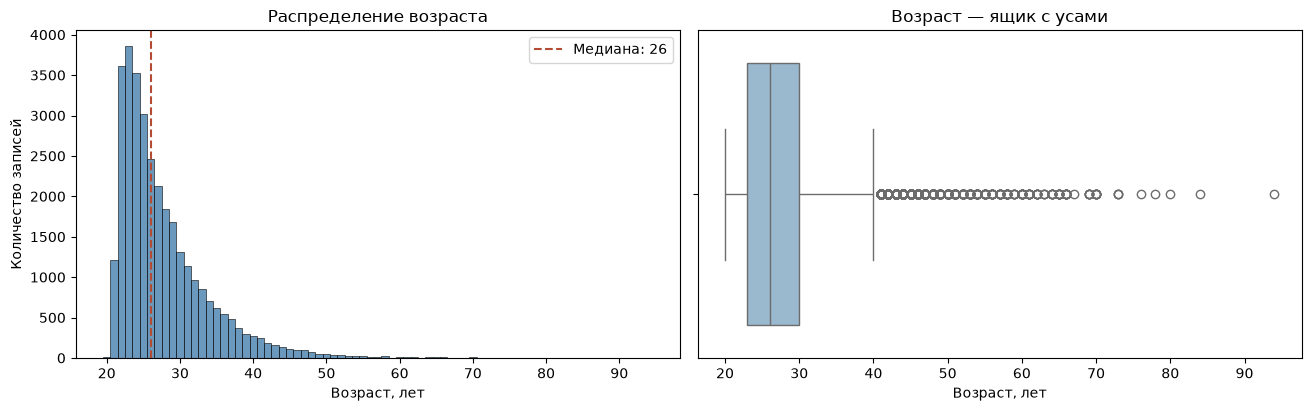

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

age = data['person_age']
q1, q3 = age.quantile([0.25, 0.75])
iqr = q3 - q1
lower_fence = q1 - 1.5 * iqr
upper_fence = q3 + 1.5 * iqr
age_outliers = (age < lower_fence) | (age > upper_fence)

age_stats = pd.concat([
    age.describe(),
    pd.Series({
        'Коэффициент асимметрии': age.skew(),
        'Верхняя граница по правилу 1,5 IQR': upper_fence,
        'Записей за границами 1,5 IQR': int(age_outliers.sum()),
        'Доля записей за границами, %': 100 * age_outliers.mean(),
    }),
]).to_frame('Значение')
display(age_stats)

fig, axes = plt.subplots(1, 2, figsize=(13, 4), constrained_layout=True)
sns.histplot(x=age, discrete=True, color='#3977a8', ax=axes[0])
axes[0].axvline(age.median(), color='#b34c32', linestyle='--',
               label=f'Медиана: {age.median():g}')
axes[0].set(title='Распределение возраста', xlabel='Возраст, лет', ylabel='Количество записей')
axes[0].legend()

sns.boxplot(x=age, color='#91bad7', ax=axes[1])
axes[1].set(title='Возраст — ящик с усами', xlabel='Возраст, лет')
plt.show()


**Выводы и решения по person_age**

<table>
<thead><tr><th>Вывод</th><th>Решение</th></tr></thead>
<tbody>
<tr><td style="background-color: #dcefe3; color: #172b20;">+ Среди заёмщиков преобладают молодые, медиана возраста — 26 лет<br>Распределение скошено вправо, старшие заёмщики встречаются реже</td><td style="background-color: #dcefe3; color: #172b20;">—</td></tr>
</tbody>
</table>

##### Тип жилья — person_home_ownership

Для номинального признака выводим частоты и доли категорий, затем строим столбчатую диаграмму


,Количество,"Доля, %"
person_home_ownership,,
RENT,16375,50.522971
MORTGAGE,13367,41.242171
OWN,2563,7.907809
OTHER,106,0.327049


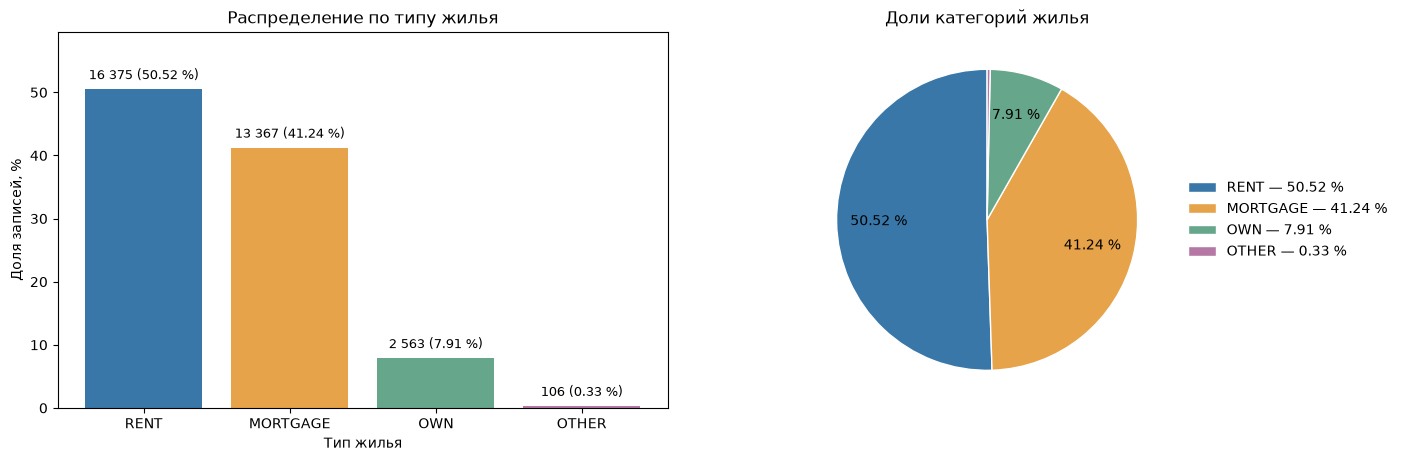

In [11]:
ownership_counts = data['person_home_ownership'].value_counts()
ownership_table = pd.DataFrame({
    'Количество': ownership_counts,
    'Доля, %': 100 * ownership_counts / len(data),
})
display(ownership_table)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), constrained_layout=True)
colors = ['#3977a8', '#e6a34a', '#66a68b', '#b578a5']
bars = axes[0].bar(ownership_table.index, ownership_table['Доля, %'], color=colors)
axes[0].bar_label(bars, labels=[
    f'{count:,} ({share:.2f} %)'.replace(',', ' ')
    for count, share in zip(ownership_table['Количество'], ownership_table['Доля, %'])
], padding=5, fontsize=9)
axes[0].set(title='Распределение по типу жилья', xlabel='Тип жилья', ylabel='Доля записей, %')
axes[0].set_ylim(0, ownership_table['Доля, %'].max() * 1.18)

wedges, _, _ = axes[1].pie(
    ownership_counts, colors=colors, startangle=90,
    autopct=lambda share: f'{share:.2f} %' if share >= 1 else '',
    pctdistance=0.72, wedgeprops={'edgecolor': 'white'},
)
axes[1].legend(wedges, [
    f'{category} — {share:.2f} %'
    for category, share in ownership_table['Доля, %'].items()
], loc='center left', bbox_to_anchor=(1, 0.5), frameon=False)
axes[1].set_title('Доли категорий жилья')
plt.show()


**Выводы и решения по person_home_ownership**

<table>
<thead><tr><th>Вывод</th><th>Решение</th></tr></thead>
<tbody>
<tr><td style="background-color: #dcefe3; color: #172b20;">+ Категории типа жилья распределены неравномерно</td><td style="background-color: #dcefe3; color: #172b20;">—</td></tr>
</tbody>
</table>


##### Годовой доход — person_income

Выводим статистики, гистограммы в обычном и логарифмическом масштабе и ящик с усами

> **Логарифмический масштаб**
>
> Равные расстояния по оси соответствуют одинаковому отношению значений, например от 10 000 до 100 000 и от 100 000 до 1 000 000
>
> Для второй гистограммы используем интервалы равной ширины по логарифму дохода, чтобы разглядеть основную массу наблюдений при длинном правом хвосте
>
> Высота столбца — количество записей в таком интервале, а не плотность на единицу дохода
>
> Меняется только отображение, значения дохода в датасете сохраняются


,Значение
count,32411
mean,65897.95517
std,52520.934765
min,4000
25%,38500
50%,55000
75%,79200
max,2039784
Коэффициент асимметрии,9.775776
"Верхняя граница по правилу 1,5 IQR",140250


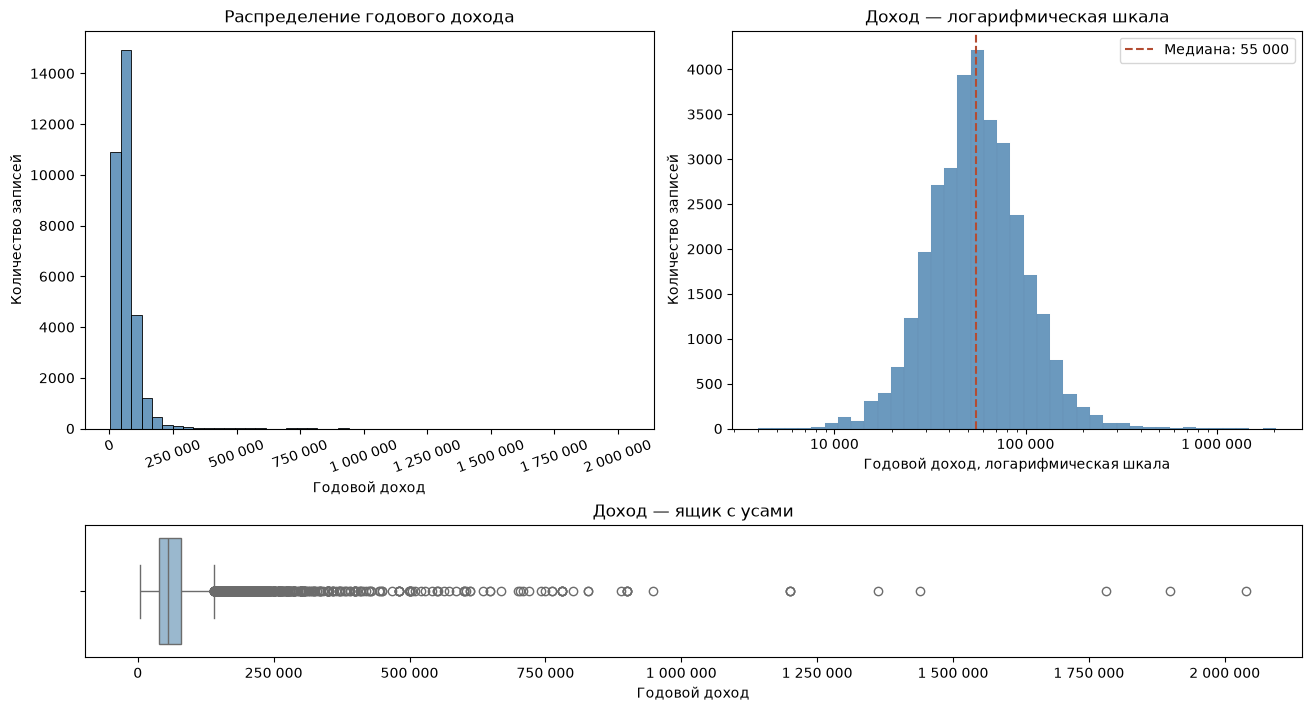

In [12]:
import numpy as np
from matplotlib.ticker import FuncFormatter

income = data['person_income']
income_q1, income_q3 = income.quantile([0.25, 0.75])
income_iqr = income_q3 - income_q1
income_lower = income_q1 - 1.5 * income_iqr
income_upper = income_q3 + 1.5 * income_iqr
income_outliers = (income < income_lower) | (income > income_upper)

income_stats = pd.concat([
    income.describe(),
    pd.Series({
        'Коэффициент асимметрии': income.skew(),
        'Верхняя граница по правилу 1,5 IQR': income_upper,
        'Записей за границами 1,5 IQR': int(income_outliers.sum()),
        'Доля записей за границами, %': 100 * income_outliers.mean(),
    }),
]).to_frame('Значение')
display(income_stats)

money_format = FuncFormatter(lambda value, _: f'{value:,.0f}'.replace(',', ' '))
fig = plt.figure(figsize=(13, 7), constrained_layout=True)
grid = fig.add_gridspec(2, 2, height_ratios=[3, 1])
income_axes = [fig.add_subplot(grid[0, 0]),
               fig.add_subplot(grid[0, 1]),
               fig.add_subplot(grid[1, :])]

sns.histplot(x=income, bins=50, color='#3977a8', ax=income_axes[0])
income_axes[0].set(title='Распределение годового дохода',
                   xlabel='Годовой доход', ylabel='Количество записей')
income_axes[0].xaxis.set_major_formatter(money_format)
income_axes[0].tick_params(axis='x', labelrotation=20)

log_bins = np.geomspace(income.min(), income.max(), 40)
sns.histplot(x=income, bins=log_bins, color='#3977a8', ax=income_axes[1])
income_axes[1].set_xscale('log')
income_axes[1].axvline(income.median(), color='#b34c32', linestyle='--',
                      label=f'Медиана: {income.median():,.0f}'.replace(',', ' '))
income_axes[1].set(title='Доход — логарифмическая шкала',
                   xlabel='Годовой доход, логарифмическая шкала', ylabel='Количество записей')
income_axes[1].xaxis.set_major_formatter(money_format)
income_axes[1].legend()

sns.boxplot(x=income, color='#91bad7', ax=income_axes[2])
income_axes[2].set(title='Доход — ящик с усами', xlabel='Годовой доход')
income_axes[2].xaxis.set_major_formatter(money_format)
plt.show()


**Выводы и решения по person_income**

<table>
<thead><tr><th>Вывод</th><th>Решение</th></tr></thead>
<tbody>
<tr><td style="background-color: #dcefe3; color: #172b20;">+ Распределение дохода сильно скошено вправо — медиана 55 000, встречаются редкие доходы свыше миллиона</td><td style="background-color: #dcefe3; color: #172b20;">Возможно, потребуется гиперпараметр предобработки — максимальный доход, выше которого исключаем записи<br>Заёмщики с высокими доходами могут существенно отличаться по кредитному поведению — эту гипотезу предстоит проверить</td></tr>
</tbody>
</table>


##### Цель кредита — loan_intent

Для номинального признака выводим частоты и доли, строим столбчатую и круговую диаграммы


,Количество,"Доля, %"
loan_intent,,
EDUCATION,6409,19.774151
MEDICAL,6042,18.641819
VENTURE,5680,17.524914
PERSONAL,5497,16.960291
DEBTCONSOLIDATION,5189,16.009997
HOMEIMPROVEMENT,3594,11.088828


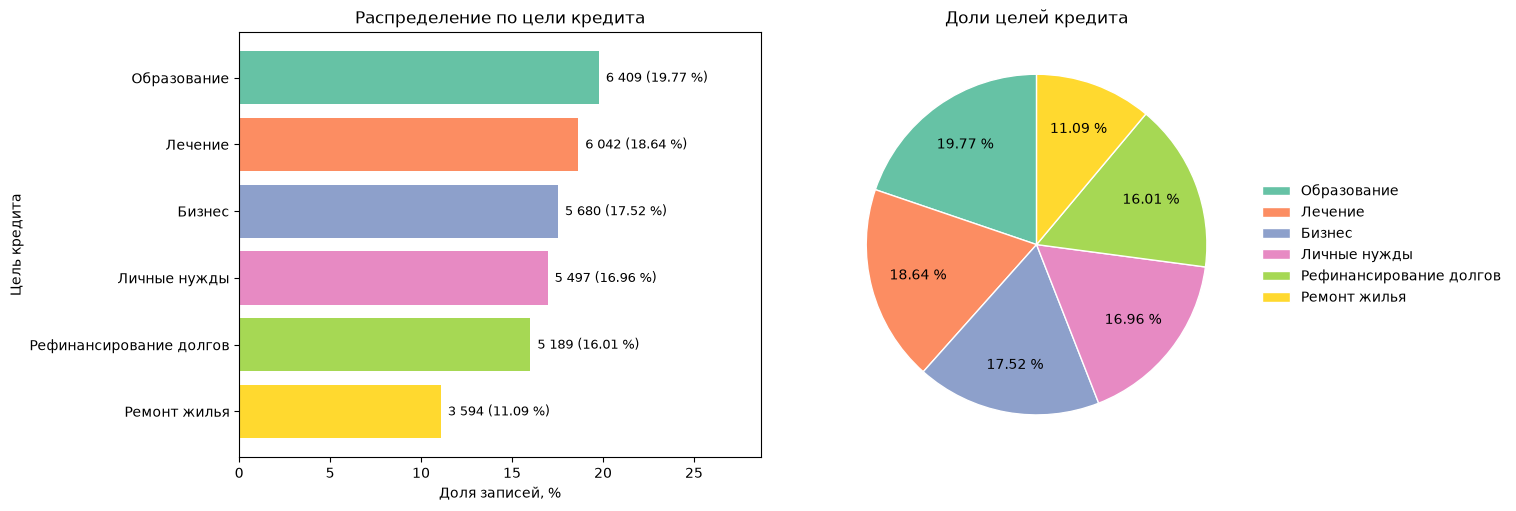

In [13]:
intent_counts = data['loan_intent'].value_counts()
intent_table = pd.DataFrame({
    'Количество': intent_counts,
    'Доля, %': 100 * intent_counts / len(data),
})
display(intent_table)

intent_labels = {
    'EDUCATION': 'Образование',
    'MEDICAL': 'Лечение',
    'VENTURE': 'Бизнес',
    'PERSONAL': 'Личные нужды',
    'DEBTCONSOLIDATION': 'Рефинансирование долгов',
    'HOMEIMPROVEMENT': 'Ремонт жилья',
}
intent_names = [intent_labels[category] for category in intent_table.index]
intent_colors = sns.color_palette('Set2', len(intent_table))
fig, axes = plt.subplots(1, 2, figsize=(15, 5), constrained_layout=True)
bars = axes[0].barh(intent_names, intent_table['Доля, %'], color=intent_colors)
axes[0].invert_yaxis()
axes[0].bar_label(bars, labels=[
    f'{count:,} ({share:.2f} %)'.replace(',', ' ')
    for count, share in zip(intent_table['Количество'], intent_table['Доля, %'])
], padding=5, fontsize=9)
axes[0].set(title='Распределение по цели кредита',
            xlabel='Доля записей, %', ylabel='Цель кредита')
axes[0].set_xlim(0, intent_table['Доля, %'].max() * 1.45)

wedges, _, _ = axes[1].pie(intent_counts, colors=intent_colors, startangle=90,
                          autopct=lambda share: f'{share:.2f} %',
                          pctdistance=0.72, wedgeprops={'edgecolor': 'white'})
axes[1].legend(wedges, intent_names, loc='center left',
               bbox_to_anchor=(1, 0.5), frameon=False)
axes[1].set_title('Доли целей кредита')
plt.show()


**Выводы и решения по loan_intent**

<table>
<thead><tr><th>Вывод</th><th>Решение</th></tr></thead>
<tbody>
<tr><td style="background-color: #dcefe3; color: #172b20;">+ Цели кредита представлены относительно равномерно — доли категорий от 11,09 % до 19,77 %</td><td style="background-color: #dcefe3; color: #172b20;">—</td></tr>
</tbody>
</table>


##### Стаж работы — person_emp_length

Выводим статистики, гистограмму с шагом один год и ящик с усами


,Значение
count,31522
mean,4.78285
std,4.037343
min,0
25%,2
50%,4
75%,7
max,41
Пропусков,889
Коэффициент асимметрии,1.249612


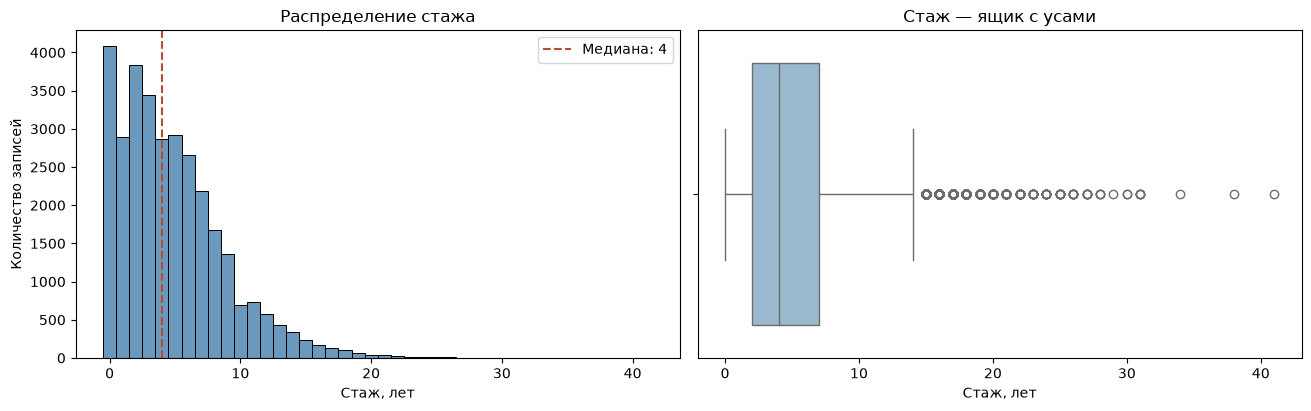

In [14]:
employment = data['person_emp_length'].dropna()
employment_q1, employment_q3 = employment.quantile([0.25, 0.75])
employment_iqr = employment_q3 - employment_q1
employment_lower = employment_q1 - 1.5 * employment_iqr
employment_upper = employment_q3 + 1.5 * employment_iqr
employment_outliers = (employment < employment_lower) | (employment > employment_upper)

employment_stats = pd.concat([
    employment.describe(),
    pd.Series({
        'Пропусков': data['person_emp_length'].isna().sum(),
        'Коэффициент асимметрии': employment.skew(),
        'Верхняя граница по правилу 1,5 IQR': employment_upper,
        'Записей за границами 1,5 IQR': int(employment_outliers.sum()),
        'Доля записей за границами среди заполненных, %': 100 * employment_outliers.mean(),
    }),
]).to_frame('Значение')
display(employment_stats)

fig, axes = plt.subplots(1, 2, figsize=(13, 4), constrained_layout=True)
sns.histplot(x=employment, discrete=True, color='#3977a8', ax=axes[0])
axes[0].axvline(employment.median(), color='#b34c32', linestyle='--',
               label=f'Медиана: {employment.median():g}')
axes[0].set(title='Распределение стажа', xlabel='Стаж, лет', ylabel='Количество записей')
axes[0].legend()
sns.boxplot(x=employment, color='#91bad7', ax=axes[1])
axes[1].set(title='Стаж — ящик с усами', xlabel='Стаж, лет')
plt.show()


**Выводы и решения по person_emp_length**

<table>
<thead><tr><th>Вывод</th><th>Решение</th></tr></thead>
<tbody>
<tr><td style="background-color: #dcefe3; color: #172b20;">+ Распределение стажа скошено вправо — медиана 4 года, наиболее частое значение 0 лет, большие значения встречаются реже</td><td style="background-color: #dcefe3; color: #172b20;">—</td></tr>
</tbody>
</table>


##### Грейд займа — loan_grade

Выводим частоты и доли, строим столбчатую и круговую диаграммы

Поскольку признак порядковый, категории располагаем от A до G, а не сортируем по частоте


,Количество,"Доля, %"
loan_grade,,
A,10703,33.022739
B,10384,32.038505
C,6436,19.857456
D,3620,11.169048
E,963,2.971213
F,241,0.743575
G,64,0.197464


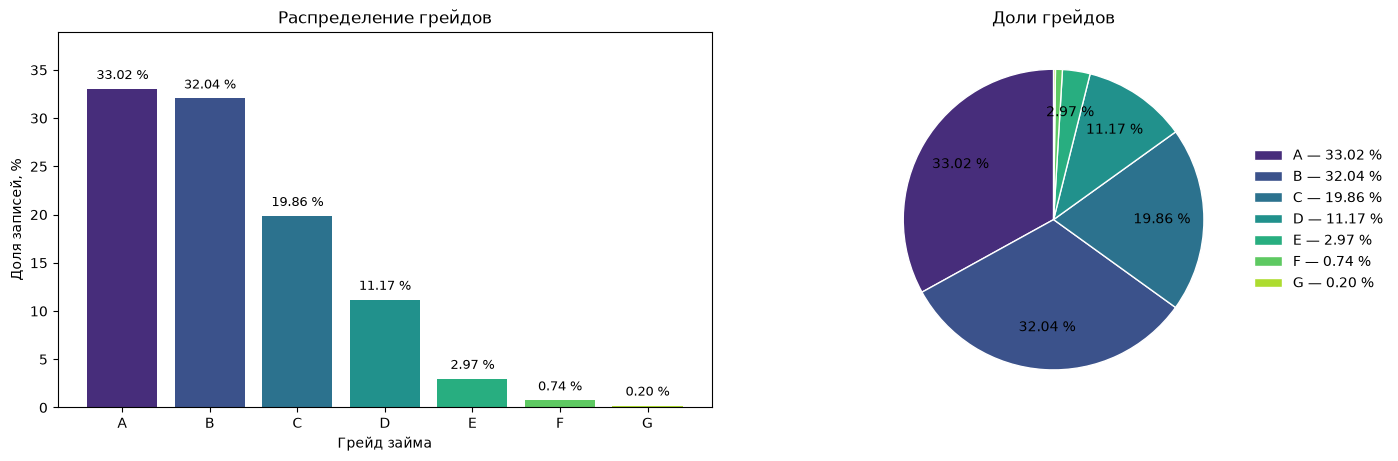

In [15]:
grade_counts = data['loan_grade'].value_counts().reindex(list('ABCDEFG'), fill_value=0)
grade_table = pd.DataFrame({
    'Количество': grade_counts,
    'Доля, %': 100 * grade_counts / len(data),
})
display(grade_table)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), constrained_layout=True)
grade_colors = sns.color_palette('viridis', len(grade_table))
bars = axes[0].bar(grade_table.index, grade_table['Доля, %'], color=grade_colors)
axes[0].bar_label(bars, labels=[f'{share:.2f} %' for share in grade_table['Доля, %']],
                  padding=5, fontsize=9)
axes[0].set(title='Распределение грейдов', xlabel='Грейд займа', ylabel='Доля записей, %')
axes[0].set_ylim(0, grade_table['Доля, %'].max() * 1.18)

wedges, _, _ = axes[1].pie(
    grade_counts, colors=grade_colors, startangle=90,
    autopct=lambda share: f'{share:.2f} %' if share >= 2 else '',
    pctdistance=0.72, wedgeprops={'edgecolor': 'white'},
)
axes[1].legend(wedges, [
    f'{grade} — {share:.2f} %' for grade, share in grade_table['Доля, %'].items()
], loc='center left', bbox_to_anchor=(1, 0.5), frameon=False)
axes[1].set_title('Доли грейдов')
plt.show()


**Выводы и решения по loan_grade**

<table>
<thead><tr><th>Вывод</th><th>Решение</th></tr></thead>
<tbody>
<tr><td style="background-color: #dcefe3; color: #172b20;">+ Грейды распределены неравномерно — A и B составляют 65,06 % записей, F и G вместе — 0,94 %</td><td style="background-color: #dcefe3; color: #172b20;">—</td></tr>
</tbody>
</table>


##### Сумма кредита — loan_amnt

Выводим статистики, гистограмму и ящик с усами


,Значение
count,32411
mean,9593.591682
std,6322.529723
min,500
25%,5000
50%,8000
75%,12250
max,35000
Пропусков,0
Коэффициент асимметрии,1.192102


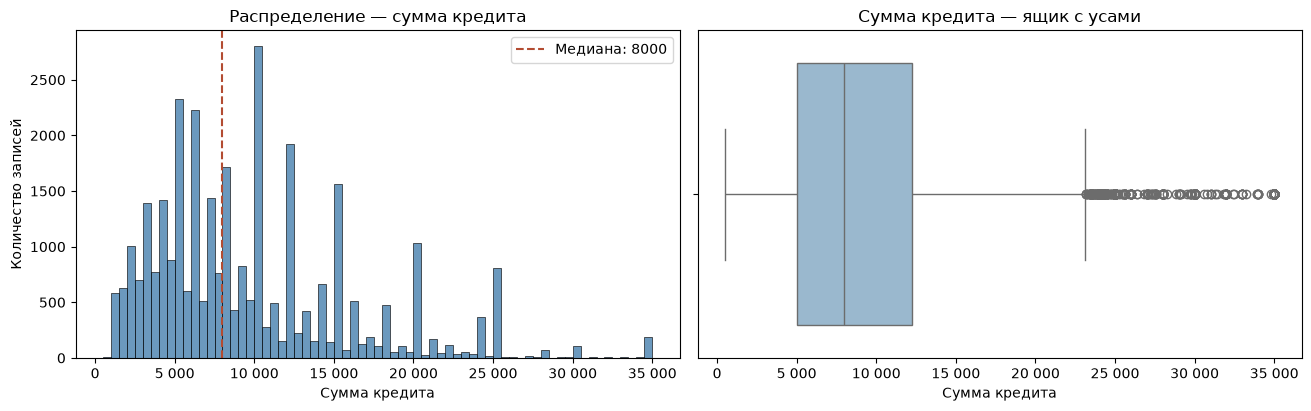

In [16]:
amount = data['loan_amnt'].dropna()
amount_q1, amount_q3 = amount.quantile([0.25, 0.75])
amount_iqr = amount_q3 - amount_q1
amount_lower = amount_q1 - 1.5 * amount_iqr
amount_upper = amount_q3 + 1.5 * amount_iqr
amount_outliers = (amount < amount_lower) | (amount > amount_upper)

amount_stats = pd.concat([
    amount.describe(),
    pd.Series({
        'Пропусков': data['loan_amnt'].isna().sum(),
        'Коэффициент асимметрии': amount.skew(),
        'Верхняя граница по правилу 1,5 IQR': amount_upper,
        'Записей за границами 1,5 IQR': int(amount_outliers.sum()),
        'Доля записей за границами среди заполненных, %': 100 * amount_outliers.mean(),
    }),
]).to_frame('Значение')
display(amount_stats)

fig, axes = plt.subplots(1, 2, figsize=(13, 4), constrained_layout=True)
sns.histplot(x=amount, binwidth=500, color='#3977a8', ax=axes[0])
axes[0].axvline(amount.median(), color='#b34c32', linestyle='--',
               label=f'Медиана: {amount.median():g}')
axes[0].set(title='Распределение — сумма кредита', xlabel='Сумма кредита', ylabel='Количество записей')
axes[0].legend()
sns.boxplot(x=amount, color='#91bad7', ax=axes[1])
axes[1].set(title='Сумма кредита — ящик с усами', xlabel='Сумма кредита')
for ax in axes:
    ax.xaxis.set_major_formatter(money_format)
plt.show()


**Выводы и решения по loan_amnt**

<table>
<thead><tr><th>Вывод</th><th>Решение</th></tr></thead>
<tbody>
<tr><td style="background-color: #dcefe3; color: #172b20;">+ Суммы кредитов распределены с правым хвостом — медиана 8 000, наиболее частая сумма 10 000</td><td style="background-color: #dcefe3; color: #172b20;">—</td></tr>
</tbody>
</table>


##### Процентная ставка — loan_int_rate

Выводим статистики, гистограмму и ящик с усами


,Значение
count,29317
mean,11.017117
std,3.241845
min,5.42
25%,7.9
50%,10.99
75%,13.47
max,23.22
Пропусков,3094
Коэффициент асимметрии,0.207114


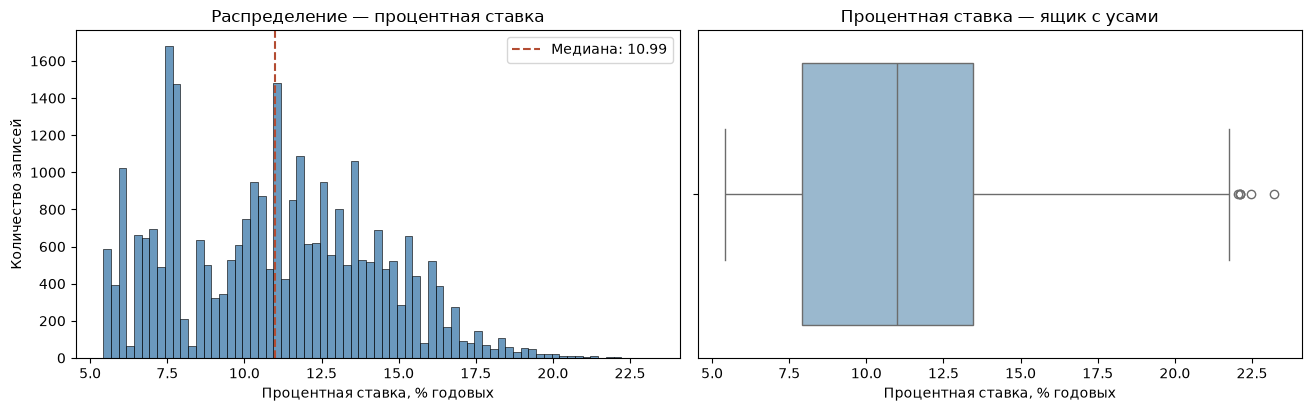

In [17]:
rate = data['loan_int_rate'].dropna()
rate_q1, rate_q3 = rate.quantile([0.25, 0.75])
rate_iqr = rate_q3 - rate_q1
rate_lower = rate_q1 - 1.5 * rate_iqr
rate_upper = rate_q3 + 1.5 * rate_iqr
rate_outliers = (rate < rate_lower) | (rate > rate_upper)

rate_stats = pd.concat([
    rate.describe(),
    pd.Series({
        'Пропусков': data['loan_int_rate'].isna().sum(),
        'Коэффициент асимметрии': rate.skew(),
        'Верхняя граница по правилу 1,5 IQR': rate_upper,
        'Записей за границами 1,5 IQR': int(rate_outliers.sum()),
        'Доля записей за границами среди заполненных, %': 100 * rate_outliers.mean(),
    }),
]).to_frame('Значение')
display(rate_stats)

fig, axes = plt.subplots(1, 2, figsize=(13, 4), constrained_layout=True)
sns.histplot(x=rate, binwidth=0.25, color='#3977a8', ax=axes[0])
axes[0].axvline(rate.median(), color='#b34c32', linestyle='--',
               label=f'Медиана: {rate.median():g}')
axes[0].set(title='Распределение — процентная ставка', xlabel='Процентная ставка, % годовых', ylabel='Количество записей')
axes[0].legend()
sns.boxplot(x=rate, color='#91bad7', ax=axes[1])
axes[1].set(title='Процентная ставка — ящик с усами', xlabel='Процентная ставка, % годовых')
plt.show()


**Выводы и решения по loan_int_rate**

<table>
<thead><tr><th>Вывод</th><th>Решение</th></tr></thead>
<tbody>
<tr><td style="background-color: #dcefe3; color: #172b20;">+ Распределение ставок имеет несколько пиков, медиана — 10,99 %, выраженной общей асимметрии нет</td><td style="background-color: #dcefe3; color: #172b20;">—</td></tr>
</tbody>
</table>


##### Доля суммы кредита от дохода — loan_percent_income

Выводим статистики, гистограмму и ящик с усами

В таблице доля записана как число от 0 до 1, на осях показываем проценты — 0,15 соответствует 15 %


,Значение
count,32411
mean,0.170259
std,0.106808
min,0
25%,0.09
50%,0.15
75%,0.23
max,0.83
Коэффициент асимметрии,1.064096
"Верхняя граница по правилу 1,5 IQR",0.44


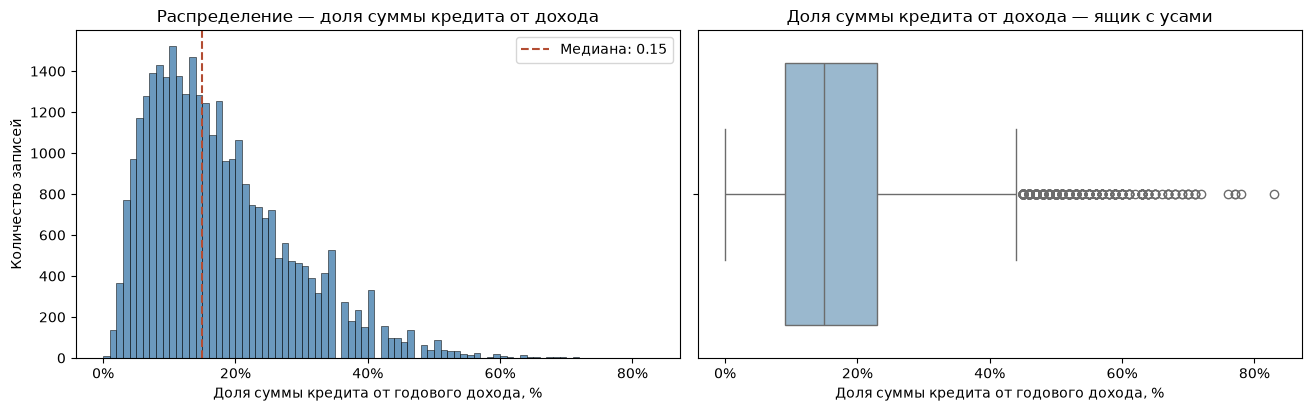

In [18]:
income_share = data['loan_percent_income'].dropna()
income_share_q1, income_share_q3 = income_share.quantile([0.25, 0.75])
income_share_iqr = income_share_q3 - income_share_q1
income_share_lower = income_share_q1 - 1.5 * income_share_iqr
income_share_upper = income_share_q3 + 1.5 * income_share_iqr
income_share_outliers = (income_share < income_share_lower) | (income_share > income_share_upper)

income_share_stats = pd.concat([
    income_share.describe(),
    pd.Series({
        'Коэффициент асимметрии': income_share.skew(),
        'Верхняя граница по правилу 1,5 IQR': income_share_upper,
        'Записей за границами 1,5 IQR': int(income_share_outliers.sum()),
        'Доля записей за границами, %': 100 * income_share_outliers.mean(),
    }),
]).to_frame('Значение')
display(income_share_stats)

fig, axes = plt.subplots(1, 2, figsize=(13, 4), constrained_layout=True)
sns.histplot(x=income_share, binwidth=0.01, color='#3977a8', ax=axes[0])
axes[0].axvline(income_share.median(), color='#b34c32', linestyle='--',
               label=f'Медиана: {income_share.median():g}')
axes[0].set(title='Распределение — доля суммы кредита от дохода', xlabel='Доля суммы кредита от годового дохода, %', ylabel='Количество записей')
axes[0].legend()
sns.boxplot(x=income_share, color='#91bad7', ax=axes[1])
axes[1].set(title='Доля суммы кредита от дохода — ящик с усами', xlabel='Доля суммы кредита от годового дохода, %')
from matplotlib.ticker import PercentFormatter
for ax in axes:
    ax.xaxis.set_major_formatter(PercentFormatter(xmax=1))
plt.show()


**Выводы и решения по loan_percent_income**

<table>
<thead><tr><th>Вывод</th><th>Решение</th></tr></thead>
<tbody>
<tr><td style="background-color: #dcefe3; color: #172b20;">+ Доля суммы кредита от годового дохода распределена с правым хвостом — медиана 15 %, большие доли встречаются реже</td><td style="background-color: #dcefe3; color: #172b20;">—</td></tr>
</tbody>
</table>


##### Прошлые дефолты — cb_person_default_on_file

Для бинарного признака выводим частоты и доли значений N — не было дефолтов, Y — были дефолты, строим столбчатую и круговую диаграммы


,Количество,"Доля, %"
cb_person_default_on_file,,
N,26681,82.320817
Y,5730,17.679183


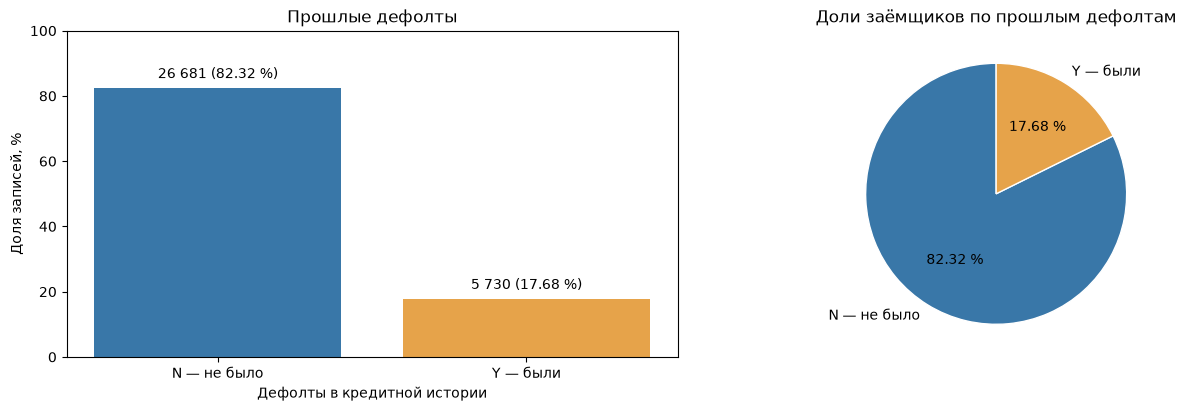

In [19]:
past_default_counts = data['cb_person_default_on_file'].value_counts().reindex(['N', 'Y'], fill_value=0)
past_default_table = pd.DataFrame({
    'Количество': past_default_counts,
    'Доля, %': 100 * past_default_counts / len(data),
})
display(past_default_table)

fig, axes = plt.subplots(1, 2, figsize=(13, 4), constrained_layout=True)
past_default_labels = ['N — не было', 'Y — были']
past_default_colors = ['#3977a8', '#e6a34a']
bars = axes[0].bar(past_default_labels, past_default_table['Доля, %'], color=past_default_colors)
axes[0].bar_label(bars, labels=[
    f'{count:,} ({share:.2f} %)'.replace(',', ' ')
    for count, share in zip(past_default_table['Количество'], past_default_table['Доля, %'])
], padding=5)
axes[0].set(title='Прошлые дефолты', xlabel='Дефолты в кредитной истории', ylabel='Доля записей, %')
axes[0].set_ylim(0, 100)
axes[1].pie(past_default_counts, labels=past_default_labels, colors=past_default_colors,
            startangle=90, autopct=lambda share: f'{share:.2f} %',
            wedgeprops={'edgecolor': 'white'})
axes[1].set_title('Доли заёмщиков по прошлым дефолтам')
plt.show()


**Выводы и решения по cb_person_default_on_file**

<table>
<thead><tr><th>Вывод</th><th>Решение</th></tr></thead>
<tbody>
<tr><td style="background-color: #dcefe3; color: #172b20;">+ У большинства заёмщиков нет зарегистрированных прошлых дефолтов — N составляет 82,32 %, Y — 17,68 %</td><td style="background-color: #dcefe3; color: #172b20;">—</td></tr>
</tbody>
</table>


##### Длина кредитной истории — cb_person_cred_hist_length

Выводим статистики, гистограмму и ящик с усами


,Значение
count,32411
mean,5.811052
std,4.057816
min,2
25%,3
50%,4
75%,8
max,30
Коэффициент асимметрии,1.658082
"Верхняя граница по правилу 1,5 IQR",15.5


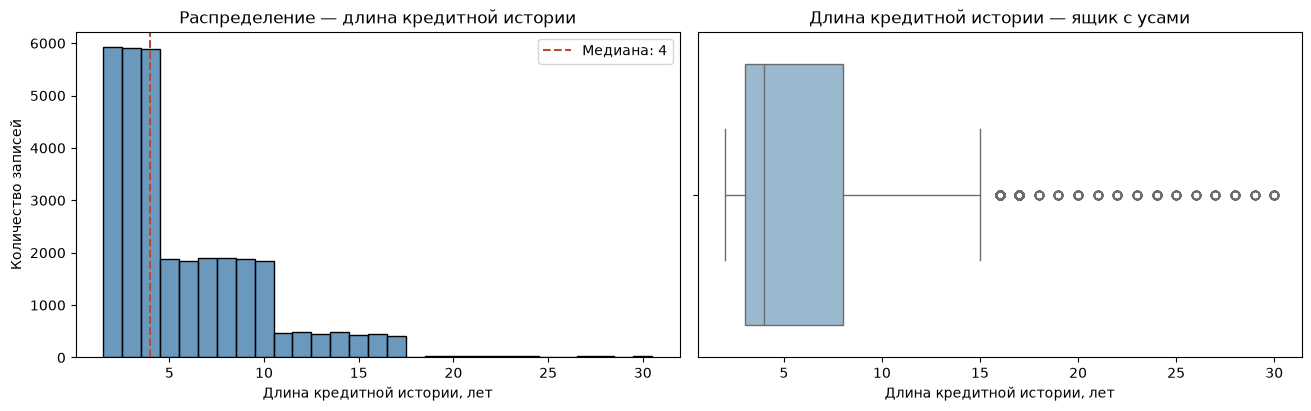

In [20]:
credit_history = data['cb_person_cred_hist_length'].dropna()
credit_history_q1, credit_history_q3 = credit_history.quantile([0.25, 0.75])
credit_history_iqr = credit_history_q3 - credit_history_q1
credit_history_lower = credit_history_q1 - 1.5 * credit_history_iqr
credit_history_upper = credit_history_q3 + 1.5 * credit_history_iqr
credit_history_outliers = (credit_history < credit_history_lower) | (credit_history > credit_history_upper)

credit_history_stats = pd.concat([
    credit_history.describe(),
    pd.Series({
        'Коэффициент асимметрии': credit_history.skew(),
        'Верхняя граница по правилу 1,5 IQR': credit_history_upper,
        'Записей за границами 1,5 IQR': int(credit_history_outliers.sum()),
        'Доля записей за границами, %': 100 * credit_history_outliers.mean(),
    }),
]).to_frame('Значение')
display(credit_history_stats)

fig, axes = plt.subplots(1, 2, figsize=(13, 4), constrained_layout=True)
sns.histplot(x=credit_history, discrete=True, color='#3977a8', ax=axes[0])
axes[0].axvline(credit_history.median(), color='#b34c32', linestyle='--',
               label=f'Медиана: {credit_history.median():g}')
axes[0].set(title='Распределение — длина кредитной истории', xlabel='Длина кредитной истории, лет', ylabel='Количество записей')
axes[0].legend()
sns.boxplot(x=credit_history, color='#91bad7', ax=axes[1])
axes[1].set(title='Длина кредитной истории — ящик с усами', xlabel='Длина кредитной истории, лет')
plt.show()


**Выводы и решения по cb_person_cred_hist_length**

<table>
<thead><tr><th>Вывод</th><th>Решение</th></tr></thead>
<tbody>
<tr><td style="background-color: #dcefe3; color: #172b20;">+ Преобладает короткая кредитная история — медиана 4 года<br>Распределение ступенчатое: внутри отдельных диапазонов частоты близки, между диапазонами резко меняются<br>Это может отражать особенности отбора или сборки данных по группам либо искусственное формирование признака</td><td style="background-color: #dcefe3; color: #172b20;">Проверить связь длины кредитной истории с возрастом — тепловая карта сочетаний значений<br>Проверить, совпадают ли группы с последовательными участками файла<br>Сравнить между группами доход, грейд, ставку и доли пропусков<br>Проверить связь с loan_status, сравнивая группы также внутри одинаковых возрастов и грейдов</td></tr>
</tbody>
</table>


##### Целевая переменная — loan_status

Выводим частоты и доли классов, строим столбчатую и круговую диаграммы

> **Баланс классов**
>
> Соотношение количества наблюдений разных классов
>
> При заметном преобладании одного класса распределение называют несбалансированным


,Количество,"Доля, %"
loan_status,,
0,25322,78.127796
1,7089,21.872204


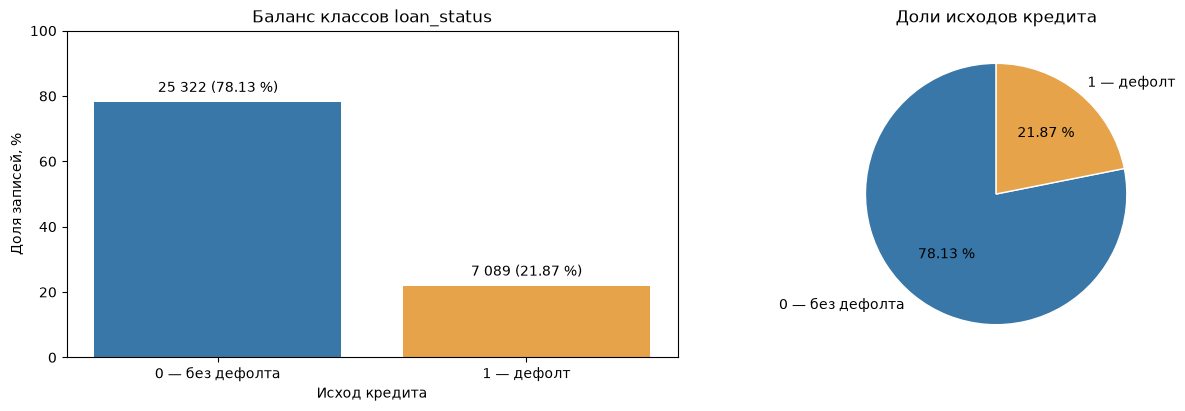

In [21]:
target_counts = data['loan_status'].value_counts().reindex([0, 1], fill_value=0)
target_table = pd.DataFrame({
    'Количество': target_counts,
    'Доля, %': 100 * target_counts / len(data),
})
display(target_table)

fig, axes = plt.subplots(1, 2, figsize=(13, 4), constrained_layout=True)
target_labels = ['0 — без дефолта', '1 — дефолт']
target_colors = ['#3977a8', '#e6a34a']
bars = axes[0].bar(target_labels, target_table['Доля, %'], color=target_colors)
axes[0].bar_label(bars, labels=[
    f'{count:,} ({share:.2f} %)'.replace(',', ' ')
    for count, share in zip(target_table['Количество'], target_table['Доля, %'])
], padding=5)
axes[0].set(title='Баланс классов loan_status', xlabel='Исход кредита', ylabel='Доля записей, %')
axes[0].set_ylim(0, 100)
axes[1].pie(target_counts, labels=target_labels, colors=target_colors,
            startangle=90, autopct=lambda share: f'{share:.2f} %',
            wedgeprops={'edgecolor': 'white'})
axes[1].set_title('Доли исходов кредита')
plt.show()


**Выводы и решения по loan_status**

<table>
<thead><tr><th>Вывод</th><th>Решение</th></tr></thead>
<tbody>
<tr><td style="background-color: #dcefe3; color: #172b20;">+ Классы несбалансированы — 78,13 % кредитов без дефолта и 21,87 % с дефолтом, соотношение примерно 3,57 к 1</td><td style="background-color: #dcefe3; color: #172b20;">—</td></tr>
</tbody>
</table>


#### Выводы и решения после 2.3

<div role="region" aria-label="Выводы и решения по этапам EDA" tabindex="0" style="max-width:100%; overflow-x:auto; margin:14px 0 22px; border:1px solid rgba(127,127,127,0.3); border-radius:10px; color:inherit;">
<table style="width:100%; min-width:700px; table-layout:fixed; border-collapse:separate; border-spacing:0; margin:0; color:inherit; background:transparent; font-size:13px; line-height:1.55; text-align:left;">
<colgroup><col style="width:58%"><col style="width:42%"></colgroup>
<thead><tr style="background:rgba(127,127,127,0.16);">
<th scope="col" style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.3); font-weight:650; text-align:left; vertical-align:top; color:inherit;">Выводы</th>
<th scope="col" style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.3); font-weight:650; text-align:left; vertical-align:top; color:inherit;">Решения</th>
</tr></thead>
<tbody>
<tr style="background:transparent;">
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">В датасете 32 581 запись, 11 признаков и одна целевая переменная</td>
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">—</td>
</tr>
<tr style="background:rgba(127,127,127,0.07);">
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">Среди признаков: 7 числовых, 2 номинальных, 1 порядковый и 1 бинарный</td>
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">—</td>
</tr>
<tr style="background:transparent;">
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">В person_emp_length (2,75 % записей) и в loan_int_rate (9.56% записей) есть пропуски</td>
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">Способ обработки пропусков выберем после анализа распределений</td>
</tr>
<tr style="background:rgba(127,127,127,0.07);">
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">Целевая переменная заполнена во всех записях и содержит только значения 0 и 1</td>
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">—</td>
</tr>
<tr style="background:transparent;">
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">Числовые признаки имеют существенно разные масштабы: максимум дохода — 6 000 000, максимум доли кредита от дохода — 0,83</td>
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">—</td>
</tr>
<tr style="background:rgba(127,127,127,0.07);">
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">Найдено 165 групп ровно по две полностью одинаковые строки: 330 записей, из них 165 повторных (0,51 % выборки)<br>Такая структура согласуется с дублированием при вводе или сборке данных</td>
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">Считать повторы техническими дубликатами и удалить, оставив по одной записи в каждой группе</td>
</tr>
<tr style="background:transparent;">
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">Возраст превышает рабочую границу 100 лет в 5 записях: 144 года в трёх записях, 123 года в двух</td>
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">Удалить эти 5 записей<br>Обработка неопределенных значений для такой малой части выборки не стоит свеч</td>
</tr>
<tr style="background:rgba(127,127,127,0.07);">
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">Верхнюю границу стажа 86 лет превышают 2 записи: в обеих стаж составляет 123 года</td>
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">Заменить недопустимый стаж пропусками, сохранив записи</td>
</tr>
<tr style="background:transparent;">
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">Для записей со стажем ≤ 86 лет выполняется условие «стаж ≤ возраст − 14»</td>
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">—</td>
</tr>
<tr style="background:rgba(127,127,127,0.07);">
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">Выполняется условие «кредитная история ≤ возраст − 16»</td>
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">—</td>
</tr>
<tr style="background:transparent;">
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">В 429 записях (1,32 % всей выборки) доля кредита отличается от отношения суммы к доходу более чем на 0,005; одним округлением до сотых эти расхождения не объясняются</td>
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">—</td>
</tr>
<tr style="background:rgba(127,127,127,0.07);">
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">Все заполненные значения возраста, стажа и длины кредитной истории целочисленные</td>
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">—</td>
</tr>
<tr style="background:rgba(65,150,100,0.10);">
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">+ После промежуточной очистки анализируем 32 411 записей</td>
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">—</td>
</tr>
<tr style="background:rgba(65,150,100,0.16);">
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">+ Среди заёмщиков преобладают молодые, медиана возраста — 26 лет<br>Распределение скошено вправо, старшие заёмщики встречаются реже</td>
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">—</td>
</tr>
<tr style="background:rgba(65,150,100,0.10);">
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">+ Категории типа жилья распределены неравномерно</td>
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">—</td>
</tr>
<tr style="background:rgba(65,150,100,0.16);">
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">+ Распределение дохода сильно скошено вправо — медиана 55 000, встречаются редкие доходы свыше миллиона</td>
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">Возможно, потребуется гиперпараметр предобработки — максимальный доход, выше которого исключаем записи<br>Заёмщики с высокими доходами могут существенно отличаться по кредитному поведению — эту гипотезу предстоит проверить</td>
</tr>
<tr style="background:rgba(65,150,100,0.10);">
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">+ Цели кредита представлены относительно равномерно — доли категорий от 11,09 % до 19,77 %</td>
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">—</td>
</tr>
<tr style="background:rgba(65,150,100,0.16);">
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">+ Распределение стажа скошено вправо — медиана 4 года, наиболее частое значение 0 лет, большие значения встречаются реже</td>
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">—</td>
</tr>
<tr style="background:rgba(65,150,100,0.10);">
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">+ Грейды распределены неравномерно — A и B составляют 65,06 % записей, F и G вместе — 0,94 %</td>
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">—</td>
</tr>
<tr style="background:rgba(65,150,100,0.16);">
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">+ Суммы кредитов распределены с правым хвостом — медиана 8 000, наиболее частая сумма 10 000</td>
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">—</td>
</tr>
<tr style="background:rgba(65,150,100,0.10);">
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">+ Распределение ставок имеет несколько пиков, медиана — 10,99 %, выраженной общей асимметрии нет</td>
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">—</td>
</tr>
<tr style="background:rgba(65,150,100,0.16);">
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">+ Доля суммы кредита от годового дохода распределена с правым хвостом — медиана 15 %, большие доли встречаются реже</td>
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">—</td>
</tr>
<tr style="background:rgba(65,150,100,0.10);">
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">+ У большинства заёмщиков нет зарегистрированных прошлых дефолтов — N составляет 82,32 %, Y — 17,68 %</td>
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">—</td>
</tr>
<tr style="background:rgba(65,150,100,0.16);">
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">+ Преобладает короткая кредитная история — медиана 4 года<br>Распределение ступенчатое: внутри отдельных диапазонов частоты близки, между диапазонами резко меняются<br>Это может отражать особенности отбора или сборки данных по группам либо искусственное формирование признака</td>
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">Проверить связь длины кредитной истории с возрастом — тепловая карта сочетаний значений<br>Проверить, совпадают ли группы с последовательными участками файла<br>Сравнить между группами доход, грейд, ставку и доли пропусков<br>Проверить связь с loan_status, сравнивая группы также внутри одинаковых возрастов и грейдов</td>
</tr>
<tr style="background:rgba(65,150,100,0.10);">
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">+ Классы несбалансированы — 78,13 % кредитов без дефолта и 21,87 % с дефолтом, соотношение примерно 3,57 к 1</td>
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">—</td>
</tr>
</tbody></table>
</div>


### 3 Разделение данных на обучающую, валидационную и тестовую выборки

**Утечка данных — data leakage** возникает, когда при подготовке или обучении модели используется информация, которая не должна быть доступна на этапе построения прогноза

Согласно [официальной документации scikit-learn](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage), тестовые данные не должны участвовать в выборе модели, отборе признаков или оценивании параметров предобработки

> As with any other type of preprocessing, feature selection should only use the training data.

Перевод: «Как и при любом другом виде предобработки, при отборе признаков следует использовать только обучающие данные»

[Официальный источник — scikit-learn, Data leakage](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage)

Перед статистическим отбором признаков, в том числе исключением признаков по взаимным корреляциям, необходимо выделить независимую тестовую выборку

Если решения принимаются по статистикам всего датасета, информация будущей тестовой части влияет на построение модели даже без непосредственного обучения на этих записях

**Использование тестовых данных при принятии решений может нарушить независимость итоговой оценки и сделать её излишне оптимистичной**

Следующий этап — разделение данных на три выборки

| Выборка | Назначение |
| --- | --- |
| **Train — обучающая** | Анализ зависимостей для отбора признаков, оценивание параметров предобработки и обучение модели |
| **Validation — валидационная** | Сравнение вариантов предобработки и моделей, выбор гиперпараметров |
| **Test — тестовая** | Итоговая оценка зафиксированного решения после завершения выбора модели и настроек |

Параметры преобразований определяем по train и применяем к validation и test без повторного оценивания по этим выборкам
**Замечание**

Все решения об отборе, удалении и преобразовании признаков принимаются исключительно на обучающей выборке (`train`)

Затем эти же решения применяются к `validation` и `test` без повторного анализа и пересчёта параметров на этих выборках

Таким образом, во всех трёх выборках сохраняются одинаковый набор, порядок и смысл признаков, а валидационные и тестовые данные не влияют на принятые решения


#### 3.1 Разделение выборки

**Scikit-learn** — библиотека Python для машинного обучения, предоставляющая инструменты предобработки данных, обучения моделей, подбора параметров и оценки качества

Функция `train_test_split` разделяет данные на непересекающиеся подвыборки

**Стратификация по целевой переменной** сохраняет приблизительно одинаковые доли классов `loan_status` в каждой выборке

Сначала выделяем train — 70 % данных, затем оставшиеся 30 % делим поровну на validation и test — по 15 % исходных данных

В обоих разбиениях используем стратификацию и `random_state=42` для воспроизводимости результата


In [22]:
from sklearn.model_selection import train_test_split

train, remaining = train_test_split(
    data,
    test_size=0.30,
    stratify=data['loan_status'],
    random_state=42,
)

validation, test = train_test_split(
    remaining,
    test_size=0.50,
    stratify=remaining['loan_status'],
    random_state=42,
)


### 4 Многомерный анализ признаков

#### 4.1 Направления анализа

Многомерный анализ направлен на исследование взаимосвязей между несколькими переменными, включая целевую переменную `loan_status`

В работе выделяем два направления — попарный анализ связей и отдельную проверку гипотез о совместных зависимостях трёх и более переменных

**Статистический анализ и принятие решений об отборе признаков выполняем только на `train`**

Полученные решения и параметры преобразований применяем к `validation` и `test` без повторного оценивания на этих выборках

##### 4.1.1 Корреляционный анализ — попарный анализ связей

Рассматриваем все возможные пары переменных, включая пары с целевой переменной

Для каждой пары вычисляем числовую меру связи, выбранную с учётом типов переменных и характера исследуемой зависимости

Результаты представляем в виде матрицы связей с тепловой картой

Попарный анализ не позволяет непосредственно оценивать совместные зависимости трёх и более переменных

##### 4.1.2 Проверка гипотез о многомерных зависимостях

Исследуем совместные зависимости трёх и более переменных

Каждая гипотеза задаёт набор переменных и предполагаемый характер их взаимосвязи — форма зависимости может быть определена заранее или оставаться неизвестной

Подходящий математический или статистический метод выбираем впоследствии с учётом содержания гипотезы

Существуют также автоматизированные методы поиска закономерностей, не требующие предварительного выбора конкретного набора переменных и формы зависимости, однако в текущей работе их использовать не планируем

#### 4.2 Выводы, гипотезы и решения перед анализом

Выводы и гипотезы храним вместе: предположения явно помечены словом «Гипотеза», план проверки указан в столбце «Решения»

Сохраняем результаты предыдущих этапов, новые гипотезы отмечаем зелёным и знаком «+», все дальнейшие проверки проводим только на `train`

<div role="region" aria-label="Накопительные выводы и решения после попарного анализа" tabindex="0" style="max-width:100%; overflow-x:auto; margin:14px 0 22px; border:1px solid rgba(127,127,127,0.3); border-radius:10px; color:inherit;">
<table style="width:100%; min-width:700px; table-layout:fixed; border-collapse:separate; border-spacing:0; margin:0; color:inherit; background:transparent; font-size:13px; line-height:1.55; text-align:left;">
<colgroup><col style="width:58%"><col style="width:42%"></colgroup>
<thead><tr style="background:rgba(127,127,127,0.16);">
<th scope="col" style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.3); font-weight:650; text-align:left; vertical-align:top; color:inherit;">Выводы</th>
<th scope="col" style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.3); font-weight:650; text-align:left; vertical-align:top; color:inherit;">Решения</th>
</tr></thead>
<tbody>
<tr style="background:transparent;">
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">В датасете 32 581 запись, 11 признаков и одна целевая переменная</td>
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">—</td>
</tr>
<tr style="background:rgba(127,127,127,0.07);">
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">Среди признаков: 7 числовых, 2 номинальных, 1 порядковый и 1 бинарный</td>
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">—</td>
</tr>
<tr style="background:transparent;">
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">В person_emp_length (2,75 % записей) и в loan_int_rate (9.56% записей) есть пропуски</td>
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">Способ обработки пропусков выберем после анализа распределений</td>
</tr>
<tr style="background:rgba(127,127,127,0.07);">
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">Целевая переменная заполнена во всех записях и содержит только значения 0 и 1</td>
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">—</td>
</tr>
<tr style="background:transparent;">
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">Числовые признаки имеют существенно разные масштабы: максимум дохода — 6 000 000, максимум доли кредита от дохода — 0,83</td>
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">—</td>
</tr>
<tr style="background:rgba(127,127,127,0.07);">
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">Найдено 165 групп ровно по две полностью одинаковые строки: 330 записей, из них 165 повторных (0,51 % выборки)<br>Такая структура согласуется с дублированием при вводе или сборке данных</td>
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">Считать повторы техническими дубликатами и удалить, оставив по одной записи в каждой группе</td>
</tr>
<tr style="background:transparent;">
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">Возраст превышает рабочую границу 100 лет в 5 записях: 144 года в трёх записях, 123 года в двух</td>
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">Удалить эти 5 записей<br>Обработка неопределенных значений для такой малой части выборки не стоит свеч</td>
</tr>
<tr style="background:rgba(127,127,127,0.07);">
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">Верхнюю границу стажа 86 лет превышают 2 записи: в обеих стаж составляет 123 года</td>
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">Заменить недопустимый стаж пропусками, сохранив записи</td>
</tr>
<tr style="background:transparent;">
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">Для записей со стажем ≤ 86 лет выполняется условие «стаж ≤ возраст − 14»</td>
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">—</td>
</tr>
<tr style="background:rgba(127,127,127,0.07);">
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">Выполняется условие «кредитная история ≤ возраст − 16»</td>
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">—</td>
</tr>
<tr style="background:transparent;">
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">В 429 записях (1,32 % всей выборки) доля кредита отличается от отношения суммы к доходу более чем на 0,005; одним округлением до сотых эти расхождения не объясняются</td>
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">—</td>
</tr>
<tr style="background:rgba(127,127,127,0.07);">
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">Все заполненные значения возраста, стажа и длины кредитной истории целочисленные</td>
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">—</td>
</tr>
<tr style="background:transparent;">
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">После промежуточной очистки анализируем 32 411 записей</td>
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">—</td>
</tr>
<tr style="background:rgba(127,127,127,0.07);">
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">Среди заёмщиков преобладают молодые, медиана возраста — 26 лет<br>Распределение скошено вправо, старшие заёмщики встречаются реже</td>
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">—</td>
</tr>
<tr style="background:transparent;">
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">Категории типа жилья распределены неравномерно</td>
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">—</td>
</tr>
<tr style="background:rgba(127,127,127,0.07);">
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">Распределение дохода сильно скошено вправо — медиана 55 000, встречаются редкие доходы свыше миллиона</td>
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">Возможно, потребуется гиперпараметр предобработки — максимальный доход, выше которого исключаем записи</td>
</tr>
<tr style="background:transparent;">
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">Цели кредита представлены относительно равномерно — доли категорий от 11,09 % до 19,77 %</td>
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">—</td>
</tr>
<tr style="background:rgba(127,127,127,0.07);">
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">Распределение стажа скошено вправо — медиана 4 года, наиболее частое значение 0 лет, большие значения встречаются реже</td>
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">—</td>
</tr>
<tr style="background:transparent;">
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">Грейды распределены неравномерно — A и B составляют 65,06 % записей, F и G вместе — 0,94 %</td>
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">—</td>
</tr>
<tr style="background:rgba(127,127,127,0.07);">
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">Суммы кредитов распределены с правым хвостом — медиана 8 000, наиболее частая сумма 10 000</td>
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">—</td>
</tr>
<tr style="background:transparent;">
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">Распределение ставок имеет несколько пиков, медиана — 10,99 %, выраженной общей асимметрии нет</td>
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">—</td>
</tr>
<tr style="background:rgba(127,127,127,0.07);">
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">Доля суммы кредита от годового дохода распределена с правым хвостом — медиана 15 %, большие доли встречаются реже</td>
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">—</td>
</tr>
<tr style="background:transparent;">
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">У большинства заёмщиков нет зарегистрированных прошлых дефолтов — N составляет 82,32 %, Y — 17,68 %</td>
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">—</td>
</tr>
<tr style="background:rgba(127,127,127,0.07);">
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">Преобладает короткая кредитная история — медиана 4 года<br>Распределение ступенчатое: внутри отдельных диапазонов частоты близки, между диапазонами резко меняются<br>Гипотеза: это может отражать особенности отбора или сборки данных по группам либо искусственное формирование признака</td>
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">Проверить, совпадают ли группы с последовательными участками файла<br>Сравнить между группами доход, грейд, ставку и доли пропусков</td>
</tr>
<tr style="background:transparent;">
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">Классы несбалансированы — 78,13 % кредитов без дефолта и 21,87 % с дефолтом, соотношение примерно 3,57 к 1</td>
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">—</td>
</tr>
<tr style="background:rgba(65,150,100,0.16);">
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">+ Гипотеза: чем хуже грейд кредита loan_grade, тем выше процентная ставка loan_int_rate</td>
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">Проверить на этапе попарного анализа — Spearman</td>
</tr>
<tr style="background:rgba(65,150,100,0.10);">
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">+ Гипотеза: возраст положительно связан с длиной кредитной истории</td>
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">Проверить на этапе попарного анализа — Pearson</td>
</tr>
<tr style="background:rgba(65,150,100,0.16);">
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">+ Гипотеза: возраст положительно связан с трудовым стажем</td>
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">Проверить на этапе попарного анализа — Pearson</td>
</tr>
<tr style="background:rgba(65,150,100,0.10);">
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">+ Гипотеза: цель кредита связана с loan_status</td>
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">Проверить на этапе попарного анализа — Cramér’s V</td>
</tr>
<tr style="background:rgba(65,150,100,0.16);">
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">+ Гипотеза: loan_percent_income ≈ loan_amnt / person_income<br>Ранее выявленные расхождения не позволяют считать формулу выполненной для всех записей</td>
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">Проверить на этапе отдельного многомерного анализа на train — сопоставить отношение с долей и изучить расхождения</td>
</tr>
<tr style="background:rgba(65,150,100,0.10);">
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">+ Гипотеза: связь прошлых дефолтов с loan_status зависит от грейда кредита<br>Исследовательское предположение, экономическое обоснование пока не установлено</td>
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">Проверить на этапе отдельного многомерного анализа — взаимодействие cb_person_default_on_file и loan_grade относительно loan_status</td>
</tr>
<tr style="background:rgba(65,150,100,0.16);">
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">+ Гипотеза: вероятность дефолта увеличивается с ростом отношения суммы кредита к доходу</td>
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">Проверить на этапе отдельного многомерного анализа — совместную связь person_income и loan_amnt с loan_status</td>
</tr>
<tr style="background:rgba(65,150,100,0.10);">
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">+ Гипотеза: грейд кредита и ставка совместно связаны с вероятностью дефолта, часть их информации может быть избыточной</td>
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">Проверить на этапе отдельного многомерного анализа — совместный вклад loan_grade и loan_int_rate относительно loan_status</td>
</tr>
<tr style="background:rgba(65,150,100,0.16);">
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">+ Гипотеза: длина кредитной истории связана с loan_status при одинаковом возрасте заёмщиков</td>
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">Проверить на этапе отдельного многомерного анализа — условную связь, дополнительно сравнить внутри одинаковых грейдов</td>
</tr>
<tr style="background:rgba(65,150,100,0.10);">
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">+ Гипотеза: заёмщики с высокими доходами отличаются по кредитному поведению</td>
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">Проверить на этапе анализа связи дохода с loan_status — отдельно изучить область высоких доходов</td>
</tr>
<tr style="background:rgba(65,150,100,0.16);">
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">+ Гипотеза: связь грейда кредита и процентной ставки имеет ступенчатую форму</td>
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">Проверить на этапе анализа формы зависимости — сравнить распределения ставки по грейдам</td>
</tr>
<tr style="background:rgba(65,150,100,0.10);">
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">+ Гипотеза: связь возраста и длины кредитной истории нелинейна</td>
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">Проверить на этапе анализа формы зависимости — тепловая карта сочетаний значений</td>
</tr>
</tbody></table>
</div>


#### 4.3 Попарный анализ ассоциаций — Pairwise Association Analysis

Рассчитываем связи всех переменных, включая `loan_status`, только на `train`, используя смысловую классификацию из раздела 0.3

##### 4.3.1 Методы по сочетаниям типов

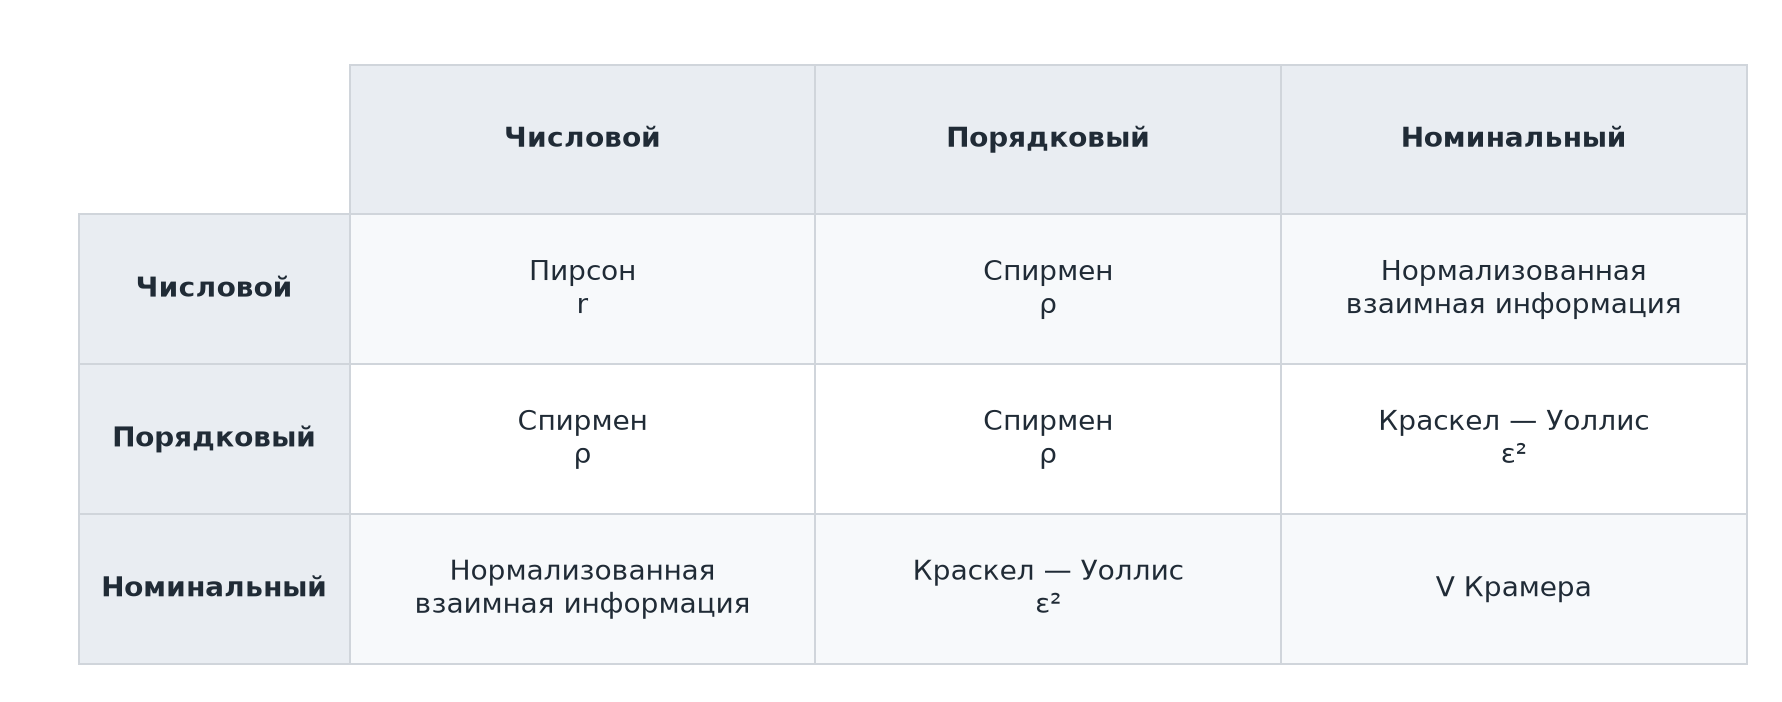

Для NMI используем I(X;Y) / H(Y), где Y — номинальная переменная независимо от расположения пары в таблице


Бинарные переменные считаем номинальными, порядок `loan_grade`: **A < B < C < D < E < F < G**

##### 4.3.2 Кратко о методах

- **Pearson:** линейная связь, r ∈ [−1, 1], сила по |r|
- **Spearman:** монотонная связь по рангам с усреднением совпадений, ρ ∈ [−1, 1], сила по |ρ|
- **Cramér’s V:** ассоциация категорий по таблице сопряжённости и χ² без поправки Йейтса, V ∈ [0, 1]
- **NMI:** общая зависимость непрерывной и дискретной переменных, оценка `mutual_info_classif` с `n_neighbors=3`, `random_state=42`, без дискретизации X, нормализация на энтропию Y в натах, диапазон [0, 1]
- **Kruskal–Wallis, ε²:** различия рангов между номинальными группами, H с поправкой на совпадения, k — число групп, n — число наблюдений, зависимость при одинаковых средних рангах групп может остаться незамеченной

Пропуски исключаем отдельно для каждой пары, неопределённые коэффициенты оставляем `NaN`, включая нулевую энтропию Y для NMI и вырожденные группы для ε²

NMI — выборочная оценка: отношение ограничиваем [0, 1], исходную оценку сохраняем в `nmi_estimates`, для категорий с единственным наблюдением возвращаем `NaN`

Исходную ε² сохраняем в матрице и `kruskal_effects`, интервалом [0, 1] ограничиваем только окраску

Значения разных мер напрямую не сравниваем, нулевые оценки не доказывают независимость

##### 4.3.3 Общие вычисления


In [23]:
from itertools import combinations_with_replacement
from scipy.stats import chi2_contingency, kruskal
from sklearn.feature_selection import mutual_info_classif


def cramers_v(left, right):
    paired = pd.concat([left, right], axis=1).dropna()
    if paired.empty:
        return np.nan
    table = pd.crosstab(paired.iloc[:, 0], paired.iloc[:, 1])
    # Удаляем ненаблюдаемые категории, если столбцы имеют dtype category
    table = table.loc[table.sum(axis=1).gt(0), table.sum(axis=0).gt(0)]
    k, m = table.shape
    if min(k, m) < 2:
        return np.nan
    chi2 = chi2_contingency(table, correction=False)[0]
    return np.sqrt(chi2 / (table.to_numpy().sum() * min(k - 1, m - 1)))


def numerical_nominal_nmi(numerical, nominal):
    paired = pd.DataFrame({'x': numerical, 'y': nominal}).dropna()
    if paired.empty:
        return np.nan, np.nan, np.nan
    labels, _ = pd.factorize(paired['y'], sort=False)
    counts = np.bincount(labels)
    probabilities = counts / counts.sum()
    entropy = float(-(probabilities * np.log(probabilities)).sum())
    if entropy <= 0:
        return np.nan, entropy, np.nan
    if paired['x'].nunique() <= 1:
        return 0.0, entropy, 0.0
    if counts.min() < 2:
        return np.nan, entropy, np.nan
    mi = mutual_info_classif(
        paired[['x']], labels, discrete_features=False,
        n_neighbors=3, random_state=42,
    )[0]
    ratio = mi / entropy
    return float(mi), entropy, float(np.clip(ratio, 0.0, 1.0))


def ordinal_nominal_kruskal(ordinal, nominal, order):
    paired = pd.DataFrame({'ordinal': ordinal, 'nominal': nominal}).dropna()
    if not paired['ordinal'].isin(order).all():
        raise ValueError('Неизвестные категории порядкового признака')
    paired['rank_code'] = paired['ordinal'].map(
        {category: rank for rank, category in enumerate(order)}
    )
    groups = [
        group['rank_code'].to_numpy(dtype=float)
        for _, group in paired.groupby('nominal', observed=True, sort=False)
        if not group.empty
    ]
    k, n = len(groups), len(paired)
    if k < 2 or n <= k or paired['rank_code'].nunique() < 2:
        return np.nan, k, n, np.nan
    try:
        h = float(kruskal(*groups).statistic)
    except ValueError:
        return np.nan, k, n, np.nan
    if not np.isfinite(h):
        return np.nan, k, n, np.nan
    effect = (h - k + 1) / (n - k)
    return h, k, n, float(effect)


# Общая матрица: инициализируем один раз перед последовательными этапами
association_columns = train.columns
association_matrix = pd.DataFrame(
    np.nan, index=association_columns, columns=association_columns, dtype=float,
)

# Используем смысловые типы из раздела 0.3, а не dtype столбцов
association_types = columns_info['Фактический тип'].reindex(association_columns)
numerical_columns = association_types.index[association_types.eq('числовой')].tolist()

# Числовые пары
pearson_matrix = train[numerical_columns].corr(method='pearson', min_periods=2)
association_matrix.loc[numerical_columns, numerical_columns] = pearson_matrix

nominal_columns = association_types.index[
    association_types.isin(['номинальный', 'бинарный'])
].tolist()

# Номинальные пары, включая бинарные
for left, right in combinations_with_replacement(nominal_columns, 2):
    value = cramers_v(train[left], train[right])
    association_matrix.loc[left, right] = value
    association_matrix.loc[right, left] = value

# Явный порядок категорий, без изменения исходного train
ordinal_orders = {'loan_grade': ['A', 'B', 'C', 'D', 'E', 'F', 'G']}
ordinal_columns = association_types.index[association_types.eq('порядковый')].tolist()

for ordinal in ordinal_columns:
    order = ordinal_orders[ordinal]
    observed = train[ordinal].dropna()
    if not observed.isin(order).all():
        raise ValueError(f'Неизвестные категории в {ordinal}')
    ordinal_values = train[ordinal].map({grade: rank for rank, grade in enumerate(order)})
    # Самокорреляция определена только при наличии разных наблюдаемых грейдов
    association_matrix.loc[ordinal, ordinal] = (
        1.0 if ordinal_values.nunique() > 1 else np.nan
    )
    for numerical in numerical_columns:
        paired = pd.DataFrame({
            'numerical': train[numerical],
            'ordinal': ordinal_values,
        }).dropna()
        value = np.nan
        if len(paired) >= 2 and paired.nunique().gt(1).all():
            value = paired.corr(method='spearman', min_periods=2).loc['numerical', 'ordinal']
        association_matrix.loc[numerical, ordinal] = value
        association_matrix.loc[ordinal, numerical] = value

# Пары порядковых переменных, включая диагональ
ordinal_data = pd.DataFrame({
    column: train[column].map({value: rank for rank, value in enumerate(ordinal_orders[column])})
    for column in ordinal_columns
}, index=train.index)
association_matrix.loc[ordinal_columns, ordinal_columns] = ordinal_data.corr(
    method='spearman', min_periods=2,
)


# Числовые × номинальные
nmi_records = []
for numerical in numerical_columns:
    for nominal in nominal_columns:
        mi, entropy, value = numerical_nominal_nmi(train[numerical], train[nominal])
        association_matrix.loc[numerical, nominal] = value
        association_matrix.loc[nominal, numerical] = value
        nmi_records.append({
            'Numerical': numerical, 'Nominal': nominal,
            'MI estimate': mi, 'H(Y)': entropy,
            'MI / H(Y)': mi / entropy if entropy > 0 else np.nan,
            'NMI': value,
        })

nmi_estimates = pd.DataFrame(nmi_records).set_index(['Numerical', 'Nominal'])

# Порядковые × номинальные
kruskal_records = []
for ordinal in ordinal_columns:
    for nominal in nominal_columns:
        h, k, n, effect = ordinal_nominal_kruskal(
            train[ordinal], train[nominal], ordinal_orders[ordinal],
        )
        association_matrix.loc[ordinal, nominal] = effect
        association_matrix.loc[nominal, ordinal] = effect
        kruskal_records.append({
            'Ordinal': ordinal, 'Nominal': nominal,
            'H': h, 'k': k, 'n': n, 'epsilon_squared': effect,
        })

kruskal_effects = pd.DataFrame(kruskal_records).set_index(['Ordinal', 'Nominal'])


##### 4.3.4 Матрица ассоциаций

Матрица данных симметрична, показываем только нижний треугольник с диагональю, подписи столбцов — снизу

Цвет и интенсивность задаются методом, числовые подписи сохраняют знак, неизвестные значения остаются пустыми, общей цветовой шкалы нет

В датасете один порядковый признак, поэтому для Ordinal × Ordinal рассчитывается только его самокорреляция, равная 1 при наличии разных наблюдаемых категорий


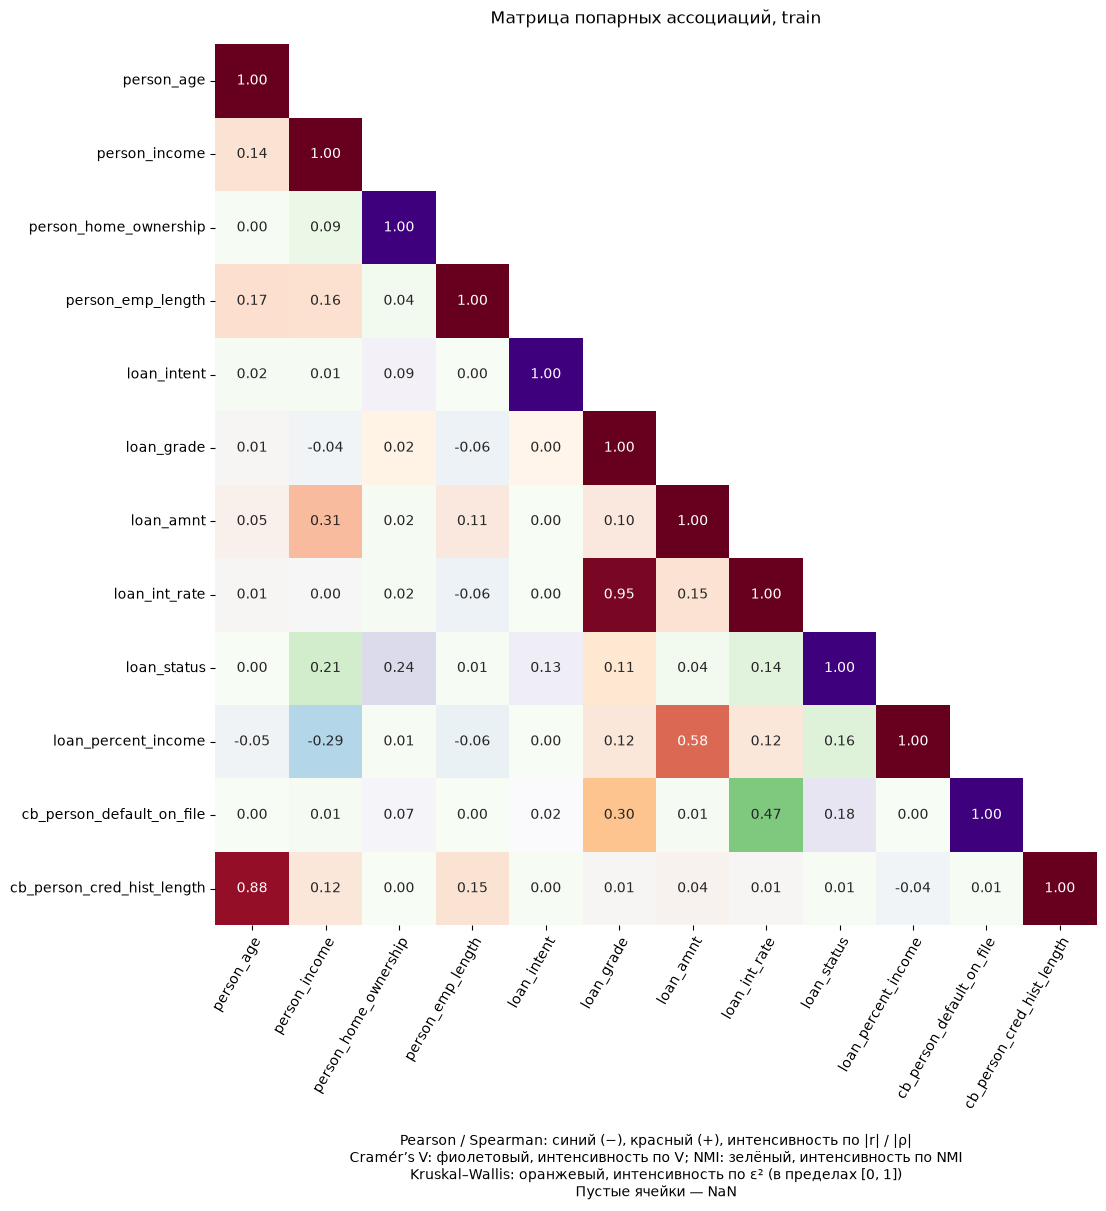

In [24]:
def plot_association_matrix(matrix, title):
    # Разные палитры обозначают разные меры, без общей цветовой шкалы
    pearson_mask = pd.DataFrame(True, index=matrix.index, columns=matrix.columns)
    pearson_mask.loc[numerical_columns, numerical_columns] = False
    ordinal = association_types.index[association_types.eq('порядковый')]
    pearson_mask.loc[numerical_columns, ordinal] = False
    pearson_mask.loc[ordinal, numerical_columns] = False
    pearson_mask.loc[ordinal, ordinal] = False
    # Скрываем верхний треугольник только при отображении
    upper_mask = np.triu(np.ones(matrix.shape, dtype=bool), k=1)
    fig, ax = plt.subplots(figsize=(14, 12), constrained_layout=True)
    sns.heatmap(
        matrix, mask=matrix.isna() | pearson_mask | upper_mask,
        cmap='RdBu_r', center=0, vmin=-1, vmax=1,
        annot=True, fmt='.2f', square=True, cbar=False,
        linewidths=0, ax=ax,
    )
    nominal_mask = pd.DataFrame(True, index=matrix.index, columns=matrix.columns)
    nominal = association_types.index[association_types.isin(['номинальный', 'бинарный'])]
    nominal_mask.loc[nominal, nominal] = False
    if (matrix.notna() & ~nominal_mask).any().any():
        sns.heatmap(
            matrix, mask=matrix.isna() | nominal_mask | upper_mask,
            cmap='Purples', vmin=0, vmax=1,
            annot=True, fmt='.2f', square=True, cbar=False,
            linewidths=0, ax=ax,
        )
    nmi_mask = pd.DataFrame(True, index=matrix.index, columns=matrix.columns)
    nmi_mask.loc[numerical_columns, nominal] = False
    nmi_mask.loc[nominal, numerical_columns] = False
    if (matrix.notna() & ~nmi_mask).any().any():
        sns.heatmap(
            matrix, mask=matrix.isna() | nmi_mask | upper_mask,
            cmap='Greens', vmin=0, vmax=1,
            annot=True, fmt='.2f', square=True, cbar=False,
            linewidths=0, ax=ax,
        )
    kw_mask = pd.DataFrame(True, index=matrix.index, columns=matrix.columns)
    kw_mask.loc[ordinal, nominal] = False
    kw_mask.loc[nominal, ordinal] = False
    if (matrix.notna() & ~kw_mask).any().any():
        sns.heatmap(
            matrix.clip(lower=0, upper=1),
            mask=matrix.isna() | kw_mask | upper_mask,
            cmap='Oranges', vmin=0, vmax=1,
            annot=matrix, fmt='.2f', square=True, cbar=False,
            linewidths=0, ax=ax,
        )
    ax.xaxis.tick_bottom()
    ax.tick_params(axis='x', labeltop=False, labelbottom=True)
    plt.setp(ax.get_xticklabels(), rotation=60, ha='right', rotation_mode='anchor')
    plt.setp(ax.get_yticklabels(), rotation=0)
    ax.set_title(title, pad=15)
    ax.set_xlabel(
        'Pearson / Spearman: синий (−), красный (+), интенсивность по |r| / |ρ|\n'
        "Cramér’s V: фиолетовый, интенсивность по V; NMI: зелёный, интенсивность по NMI\nKruskal–Wallis: оранжевый, интенсивность по ε² (в пределах [0, 1])\nПустые ячейки — NaN",
        labelpad=15,
    )
    plt.show()


plot_association_matrix(
    association_matrix,
    'Матрица попарных ассоциаций, train',
)


#### Выводы и решения после 4.3

Выводы и гипотезы храним вместе: предположения явно помечены словом «Гипотеза», план проверки указан в столбце «Решения»

Новые результаты получены только на `train` — 22 687 записей, для пар с пропусками наблюдений меньше

Четыре рассмотренные попарные гипотезы снимаем с проверки: красные строки со знаком «−» показывают, какие предположения заменены результатами ниже, в следующую накопительную таблицу их не переносим

Непроверенные части предположений о форме зависимостей и совместных связях остаются отдельными гипотезами, новые выводы отмечены зелёным и знаком «+»

Это описательные результаты EDA, а не формальное доказательство гипотез, коэффициенты разных типов напрямую не сравниваем, выводов о причинности и отборе признаков не делаем

<div role="region" aria-label="Накопительные выводы и решения после попарного анализа" tabindex="0" style="max-width:100%; overflow-x:auto; margin:14px 0 22px; border:1px solid rgba(127,127,127,0.3); border-radius:10px; color:inherit;">
<table style="width:100%; min-width:700px; table-layout:fixed; border-collapse:separate; border-spacing:0; margin:0; color:inherit; background:transparent; font-size:13px; line-height:1.55; text-align:left;">
<colgroup><col style="width:58%"><col style="width:42%"></colgroup>
<thead><tr style="background:rgba(127,127,127,0.16);">
<th scope="col" style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.3); font-weight:650; text-align:left; vertical-align:top; color:inherit;">Выводы</th>
<th scope="col" style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.3); font-weight:650; text-align:left; vertical-align:top; color:inherit;">Решения</th>
</tr></thead>
<tbody>
<tr style="background:transparent;">
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">В датасете 32 581 запись, 11 признаков и одна целевая переменная</td>
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">—</td>
</tr>
<tr style="background:rgba(127,127,127,0.07);">
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">Среди признаков: 7 числовых, 2 номинальных, 1 порядковый и 1 бинарный</td>
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">—</td>
</tr>
<tr style="background:transparent;">
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">В person_emp_length (2,75 % записей) и в loan_int_rate (9.56% записей) есть пропуски</td>
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">Способ обработки пропусков выберем после анализа распределений</td>
</tr>
<tr style="background:rgba(127,127,127,0.07);">
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">Целевая переменная заполнена во всех записях и содержит только значения 0 и 1</td>
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">—</td>
</tr>
<tr style="background:transparent;">
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">Числовые признаки имеют существенно разные масштабы: максимум дохода — 6 000 000, максимум доли кредита от дохода — 0,83</td>
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">—</td>
</tr>
<tr style="background:rgba(127,127,127,0.07);">
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">Найдено 165 групп ровно по две полностью одинаковые строки: 330 записей, из них 165 повторных (0,51 % выборки)<br>Такая структура согласуется с дублированием при вводе или сборке данных</td>
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">Считать повторы техническими дубликатами и удалить, оставив по одной записи в каждой группе</td>
</tr>
<tr style="background:transparent;">
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">Возраст превышает рабочую границу 100 лет в 5 записях: 144 года в трёх записях, 123 года в двух</td>
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">Удалить эти 5 записей<br>Обработка неопределенных значений для такой малой части выборки не стоит свеч</td>
</tr>
<tr style="background:rgba(127,127,127,0.07);">
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">Верхнюю границу стажа 86 лет превышают 2 записи: в обеих стаж составляет 123 года</td>
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">Заменить недопустимый стаж пропусками, сохранив записи</td>
</tr>
<tr style="background:transparent;">
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">Для записей со стажем ≤ 86 лет выполняется условие «стаж ≤ возраст − 14»</td>
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">—</td>
</tr>
<tr style="background:rgba(127,127,127,0.07);">
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">Выполняется условие «кредитная история ≤ возраст − 16»</td>
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">—</td>
</tr>
<tr style="background:transparent;">
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">В 429 записях (1,32 % всей выборки) доля кредита отличается от отношения суммы к доходу более чем на 0,005; одним округлением до сотых эти расхождения не объясняются</td>
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">—</td>
</tr>
<tr style="background:rgba(127,127,127,0.07);">
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">Все заполненные значения возраста, стажа и длины кредитной истории целочисленные</td>
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">—</td>
</tr>
<tr style="background:transparent;">
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">После промежуточной очистки анализируем 32 411 записей</td>
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">—</td>
</tr>
<tr style="background:rgba(127,127,127,0.07);">
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">Среди заёмщиков преобладают молодые, медиана возраста — 26 лет<br>Распределение скошено вправо, старшие заёмщики встречаются реже</td>
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">—</td>
</tr>
<tr style="background:transparent;">
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">Категории типа жилья распределены неравномерно</td>
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">—</td>
</tr>
<tr style="background:rgba(127,127,127,0.07);">
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">Распределение дохода сильно скошено вправо — медиана 55 000, встречаются редкие доходы свыше миллиона</td>
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">Возможно, потребуется гиперпараметр предобработки — максимальный доход, выше которого исключаем записи</td>
</tr>
<tr style="background:transparent;">
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">Цели кредита представлены относительно равномерно — доли категорий от 11,09 % до 19,77 %</td>
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">—</td>
</tr>
<tr style="background:rgba(127,127,127,0.07);">
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">Распределение стажа скошено вправо — медиана 4 года, наиболее частое значение 0 лет, большие значения встречаются реже</td>
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">—</td>
</tr>
<tr style="background:transparent;">
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">Грейды распределены неравномерно — A и B составляют 65,06 % записей, F и G вместе — 0,94 %</td>
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">—</td>
</tr>
<tr style="background:rgba(127,127,127,0.07);">
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">Суммы кредитов распределены с правым хвостом — медиана 8 000, наиболее частая сумма 10 000</td>
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">—</td>
</tr>
<tr style="background:transparent;">
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">Распределение ставок имеет несколько пиков, медиана — 10,99 %, выраженной общей асимметрии нет</td>
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">—</td>
</tr>
<tr style="background:rgba(127,127,127,0.07);">
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">Доля суммы кредита от годового дохода распределена с правым хвостом — медиана 15 %, большие доли встречаются реже</td>
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">—</td>
</tr>
<tr style="background:transparent;">
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">У большинства заёмщиков нет зарегистрированных прошлых дефолтов — N составляет 82,32 %, Y — 17,68 %</td>
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">—</td>
</tr>
<tr style="background:rgba(127,127,127,0.07);">
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">Преобладает короткая кредитная история — медиана 4 года<br>Распределение ступенчатое: внутри отдельных диапазонов частоты близки, между диапазонами резко меняются<br>Гипотеза: это может отражать особенности отбора или сборки данных по группам либо искусственное формирование признака</td>
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">Проверить, совпадают ли группы с последовательными участками файла<br>Сравнить между группами доход, грейд, ставку и доли пропусков</td>
</tr>
<tr style="background:transparent;">
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">Классы несбалансированы — 78,13 % кредитов без дефолта и 21,87 % с дефолтом, соотношение примерно 3,57 к 1</td>
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">—</td>
</tr>
<tr style="background:rgba(200,65,65,0.16);">
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">− Гипотеза: чем хуже грейд кредита loan_grade, тем выше процентная ставка loan_int_rate</td>
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">Снята с проверки на этом этапе — заменена наблюдаемым результатом ниже, без утверждения о статистическом доказательстве</td>
</tr>
<tr style="background:rgba(200,65,65,0.16);">
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">− Гипотеза: возраст положительно связан с длиной кредитной истории</td>
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">Снята с проверки на этом этапе — заменена наблюдаемым результатом ниже, без утверждения о статистическом доказательстве</td>
</tr>
<tr style="background:rgba(200,65,65,0.16);">
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">− Гипотеза: возраст положительно связан с трудовым стажем</td>
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">Снята с проверки на этом этапе — заменена наблюдаемым результатом ниже, без утверждения о статистическом доказательстве</td>
</tr>
<tr style="background:rgba(200,65,65,0.16);">
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">− Гипотеза: цель кредита связана с loan_status</td>
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">Снята с проверки на этом этапе — заменена наблюдаемым результатом ниже, без утверждения о статистическом доказательстве</td>
</tr>
<tr style="background:rgba(127,127,127,0.07);">
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">Гипотеза: loan_percent_income ≈ loan_amnt / person_income<br>Ранее выявленные расхождения не позволяют считать формулу выполненной для всех записей</td>
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">Проверить на этапе отдельного многомерного анализа на train — сопоставить отношение с долей и изучить расхождения</td>
</tr>
<tr style="background:transparent;">
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">Гипотеза: связь прошлых дефолтов с loan_status зависит от грейда кредита<br>Исследовательское предположение, экономическое обоснование пока не установлено</td>
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">Проверить на этапе отдельного многомерного анализа — взаимодействие cb_person_default_on_file и loan_grade относительно loan_status</td>
</tr>
<tr style="background:rgba(127,127,127,0.07);">
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">Гипотеза: вероятность дефолта увеличивается с ростом отношения суммы кредита к доходу</td>
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">Проверить на этапе отдельного многомерного анализа — совместную связь person_income и loan_amnt с loan_status</td>
</tr>
<tr style="background:transparent;">
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">Гипотеза: грейд кредита и ставка совместно связаны с вероятностью дефолта, часть их информации может быть избыточной</td>
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">Проверить на этапе отдельного многомерного анализа — совместный вклад loan_grade и loan_int_rate относительно loan_status</td>
</tr>
<tr style="background:rgba(127,127,127,0.07);">
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">Гипотеза: длина кредитной истории связана с loan_status при одинаковом возрасте заёмщиков</td>
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">Проверить на этапе отдельного многомерного анализа — условную связь, дополнительно сравнить внутри одинаковых грейдов</td>
</tr>
<tr style="background:transparent;">
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">Гипотеза: заёмщики с высокими доходами отличаются по кредитному поведению</td>
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">Проверить на этапе анализа связи дохода с loan_status — отдельно изучить область высоких доходов</td>
</tr>
<tr style="background:rgba(127,127,127,0.07);">
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">Гипотеза: связь грейда кредита и процентной ставки имеет ступенчатую форму</td>
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">Проверить на этапе анализа формы зависимости — сравнить распределения ставки по грейдам</td>
</tr>
<tr style="background:transparent;">
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">Гипотеза: связь возраста и длины кредитной истории нелинейна</td>
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">Проверить на этапе анализа формы зависимости — тепловая карта сочетаний значений</td>
</tr>
<tr style="background:rgba(65,150,100,0.16);">
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">+ На train между loan_grade и loan_int_rate наблюдается сильная положительная монотонная связь — Spearman ρ = 0,947<br>Худшему грейду соответствует более высокая ставка</td>
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">—</td>
</tr>
<tr style="background:rgba(65,150,100,0.10);">
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">+ Возраст и длина кредитной истории имеют сильную положительную линейную связь — Pearson r = 0,879<br>Это не объясняет ступенчатое распределение длины истории</td>
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">—</td>
</tr>
<tr style="background:rgba(65,150,100,0.16);">
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">+ Возраст и стаж имеют небольшую положительную линейную корреляцию — Pearson r = 0,171</td>
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">—</td>
</tr>
<tr style="background:rgba(65,150,100,0.10);">
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">+ Между целью кредита и loan_status наблюдается ассоциация — Cramér’s V = 0,125<br>Коэффициент не указывает, какие цели связаны с большей долей дефолтов</td>
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">—</td>
</tr>
<tr style="background:rgba(65,150,100,0.16);">
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">+ Для суммы кредита и доли кредита от дохода Pearson r = 0,577, для дохода и этой доли r = −0,294</td>
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">—</td>
</tr>
<tr style="background:rgba(65,150,100,0.10);">
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">+ Прошлый дефолт связан с процентной ставкой по оценке NMI = 0,470, с грейдом кредита — по ε² = 0,296<br>Методы отражают разные виды связи, их значения напрямую не сравниваем</td>
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">—</td>
</tr>
<tr style="background:rgba(65,150,100,0.16);">
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">+ Для loan_status и типа жилья Cramér’s V = 0,243, для loan_status и прошлого дефолта V = 0,178<br>Коэффициенты показывают ассоциацию, но не её направление и не причинность</td>
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">—</td>
</tr>
<tr style="background:rgba(65,150,100,0.10);">
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">+ Для числовых признаков и loan_status получены оценки NMI: доход — 0,210, доля кредита от дохода — 0,156, ставка — 0,143, сумма — 0,036<br>Это доли неопределённости loan_status, оцениваемые по каждому признаку отдельно, они не складываются и не определяют важность признаков в совместной модели</td>
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">—</td>
</tr>
<tr style="background:rgba(65,150,100,0.16);">
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">+ Между loan_grade и loan_status получен размер эффекта Краскела — Уоллиса ε² = 0,109<br>Он отражает различия рангов грейда между классами, но не задаёт направление изменения вероятности дефолта</td>
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">—</td>
</tr>
<tr style="background:rgba(65,150,100,0.10);">
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">+ Подпись 0.00 не означает установленного отсутствия связи<br>Например, для дохода и ставки Pearson r = 0,001817, для грейда и цели кредита ε² = 0,000542 — значения округлены<br>Нулевая оценка NMI также не доказывает независимость: оцениватель заменяет отрицательные выборочные оценки взаимной информации нулём</td>
<td style="padding:14px 12px; border-bottom:1px solid rgba(127,127,127,0.2); vertical-align:top; text-align:left; white-space:normal; overflow-wrap:anywhere; color:inherit;">—</td>
</tr>
</tbody></table>
</div>


In [25]:
__v_finish('/var/folders/q7/qm8kzvrd7g15k7rc898r7zhw0000gp/T/notebook-generated-vxd5vwn6/snapshot.pkl')